# C02i — Downward-pressure schedule comparison
Test constant, linear and sigmoid probability thresholds with the **same eight cases, C02h human-prefix references, warm-up, model, prompt, hysteresis, and boundary policy**. Genre/domain reference logic is unchanged. Only the **decrease-uniqueness schedule** varies; the increase schedule stays exactly as frozen in C02h.

Your inspection found no significant degradation in the three reviewed C02h examples. That does not automatically validate the stronger rewrites: every condition exports full text for review.

**Eight controller settings plus an ordinary baseline**
- C02h sigmoid: minimum .005, maximum .10, slope 4, midpoint 1.
- Constant θ: .020, .005, .001.
- Linear matched: .10 at Q=0 to .005 at Q=2, clamped outside.
- Linear strong: .05 at Q=0 to .001 at Q=1.5, clamped outside.
- Sigmoid strong: minimum .001, maximum .05, slope 4, midpoint .75.
- Sigmoid steep: same bounds/midpoint as strong, slope 8.

The matched linear/C02h sigmoid have the same bounds and midpoint value. The strong linear and strong sigmoids also share bounds and midpoint value. They are not matched for integrated pressure. Steepness alone is not uniformly stronger: sigmoid schedules cross at their shared midpoint. Plots/table below make these differences explicit.

Lower θ expands candidate eligibility; it does not guarantee a successful replacement, semantic preservation or better tracking. The existing rule remains: search only when the ordinary word conflicts with the active mode; revert it only after eligible alternatives are exhausted. No intervention, output-length, beam, depth or branch-count budget is added. Context/OOM/interruption stays incomplete, never success.

**Design and interpretation:** compare all settings, with no detector-based selection. Report raw per-case outcomes, equal-weight case averages, above-band error, below-band overshoot, band occupancy, excursion lengths, support coverage, runtime/search work, and output lengths. The primary comparison uses the same post-warm-up word positions across all completed variants and baseline within each case. Full-text metrics and pairwise common-position comparisons are also provided. A separate cutoff per case is defined by the shortest output and last supported human position; short outputs can shrink this comparison window, so coverage and lengths must be inspected. Incomplete cases remain visible, not silently counted as successful.

This is an exploratory robustness/sensitivity experiment on eight previously inspected cases. It can falsify failure claims or expose parameter sensitivity; it cannot establish a general proof or held-out performance. Model generation runs locally and can be expensive at θ=.001.

In [1]:
IMPLEMENTATION_SHA256 = 'a471d3a9d53a69666d1c102d2a6a0ecf168e58b5363fe325c3f1cf982a5c9238'
from pathlib import Path
import json, hashlib, math, os, time, uuid, html, inspect
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = Path('..')
BASE = ROOT / 'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR = ROOT / 'results/causal/C02e2_raid_feature_guided'
PREVIOUS_OUT = ROOT / 'results/causal/C02h_adaptive_prefix_control'
OUT = ROOT / 'results/causal/C02i_downward_pressure_sweep'
# Reuse baseline and C02h-control only after strict input/environment validation.
REUSE_C02H = True
OUT.mkdir(parents=True, exist_ok=True)

def digest(x):
    return hashlib.sha256(json.dumps(x,sort_keys=True,ensure_ascii=False,allow_nan=False).encode()).hexdigest()

def write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False))
    os.replace(tmp,path)
import copy
# Only the decrease schedule varies. The increase schedule is frozen from C02h.
DECREASE_SCHEDULES = {
    'h_sigmoid': dict(family='sigmoid',minimum=.005,maximum=.10,slope=4.,midpoint=1.),
    'constant_020': dict(family='constant',theta=.020),
    'constant_005': dict(family='constant',theta=.005),
    'constant_001': dict(family='constant',theta=.001),
    'linear_matched': dict(family='linear',minimum=.005,maximum=.10,q_start=0.,q_end=2.),
    'linear_strong': dict(family='linear',minimum=.001,maximum=.05,q_start=0.,q_end=1.5),
    'sigmoid_strong': dict(family='sigmoid',minimum=.001,maximum=.05,slope=4.,midpoint=.75),
    'sigmoid_steep': dict(family='sigmoid',minimum=.001,maximum=.05,slope=8.,midpoint=.75),
}

CONDITION_ORDER=['baseline']+list(DECREASE_SCHEDULES)
RUN_CONDITIONS=CONDITION_ORDER.copy()  # Select a subset to run/resume; reports still show the full plan.
assert set(RUN_CONDITIONS)<=set(CONDITION_ORDER)

## Load the frozen C02h inputs
Requires your completed C02h output directory. This imports the exact selected human passages and stored curves instead of selecting new ones. If versions/model settings differ, the notebook stops before comparing old and new runs. Fix the environment first; it will not quietly reuse mismatched results.

In [2]:
# Human prefix references and adaptive control helpers.
import math

def prefix_curve(word_lists, minimum_support=15):
    """Empirical quantiles at absolute alphabetic-word position; no extrapolation."""
    import numpy as np
    trajectories=[]
    for words in word_lists:
        seen=set(); trajectory=[]
        for w,word in enumerate(words,1):
            seen.add(word.lower()); trajectory.append(len(seen)/w)
        trajectories.append(trajectory)
    curve={}
    for w in range(1,max(map(len,trajectories),default=0)+1):
        ratios=[t[w-1] for t in trajectories if len(t)>=w]
        n=len(ratios)
        entry=dict(W=w,reference_n=n,supported=n>=minimum_support)
        if entry['supported']:
            entry.update(zip(['H_h30','H_h10','H_median','H_a10'],
                map(float,np.quantile(ratios,[.2,.4,.5,.6],method='linear'))))
        curve[str(w)]=entry
    return curve

def reference_at(curve,w):
    return curve.get(str(w),dict(W=w,reference_n=0,supported=False))

def adaptive_mode(previous,V,W,warmup_words,ref):
    if W<warmup_words or W==0: return 'normal'
    if not ref['supported']: return 'unsupported'
    k=V/W
    if previous=='increase' and k<ref['H_h10']: return 'increase'
    if previous=='decrease' and k>ref['H_h10']: return 'decrease'
    if k<ref['H_h30']: return 'increase'
    if k>ref['H_a10']: return 'decrease'
    return 'normal'

def adaptive_theta(mode,k,w,ref,schedules):
    if mode not in ('increase','decrease'): return None,None
    width=(ref['H_a10']-ref['H_h10'] if mode=='decrease'
           else ref['H_h10']-ref['H_h30'])
    q=max(0.,(k-ref['H_h10'] if mode=='decrease' else ref['H_h10']-k)/max(width,1/w))
    s=schedules[mode]
    assert 0<s['minimum']<=s['maximum']<=1 and s['slope']>0
    z=s['slope']*(q-s['midpoint'])
    sigmoid=math.exp(-z)/(1+math.exp(-z)) if z>=0 else 1/(1+math.exp(z))
    return float(s['minimum']+(s['maximum']-s['minimum'])*sigmoid),float(q)

def trajectory_metrics(trajectory,warmup_words):
    # Include word warmup+1 onward: these are the words eligible for intervention.
    eligible=[t for t in trajectory if t['W_after']>warmup_words]
    supported=[t for t in eligible if t['reference_after']['supported']]
    distances=[]; normalized=[]; longest=run=0
    for t in eligible:
        r=t['reference_after']
        if not r['supported']:
            run=0;continue
        k=t['k_after']; d=max(r['H_h30']-k,0.,k-r['H_a10'])
        distances.append(d)
        normalized.append(d/max(r['H_a10']-r['H_h30'],1/t['W_after']))
        run=run+1 if d>0 else 0;longest=max(longest,run)
    n=len(supported)
    return dict(post_warmup_words=len(eligible),supported_words=n,
        unsupported_words=len(eligible)-n,
        reference_coverage=n/len(eligible) if eligible else None,
        fraction_in_band=sum(d==0 for d in distances)/n if n else None,
        mean_band_distance=sum(distances)/n if n else None,
        mean_normalized_band_distance=sum(normalized)/n if n else None,
        maximum_band_distance=max(distances) if n else None,
        longest_outside_run=longest if n else None)


import math

def schedule_value(q,s):
    family=s.get('family','sigmoid')
    if family=='constant':
        theta=float(s['theta'])
        if not 0<theta<=1:raise ValueError('Constant theta must be in (0,1].')
        return theta
    lo,hi=float(s['minimum']),float(s['maximum'])
    if not 0<lo<=hi<=1:raise ValueError('Invalid theta bounds.')
    q=max(0.,float(q))
    if family=='sigmoid':
        if s['slope']<=0:raise ValueError('Sigmoid slope must be positive.')
        z=s['slope']*(q-s['midpoint'])
        factor=math.exp(-z)/(1+math.exp(-z)) if z>=0 else 1/(1+math.exp(z))
    elif family=='linear':
        if s['q_end']<=s['q_start']:raise ValueError('Linear q_end must exceed q_start.')
        factor=max(0.,min(1.,(s['q_end']-q)/(s['q_end']-s['q_start'])))
    else:raise ValueError(f'Unknown schedule family: {family}')
    return float(lo+(hi-lo)*factor)

def adaptive_theta(mode,k,w,ref,schedules):
    if mode not in ('increase','decrease'):return None,None
    width=ref['H_a10']-ref['H_h10'] if mode=='decrease' else ref['H_h10']-ref['H_h30']
    q=max(0.,(k-ref['H_h10'] if mode=='decrease' else ref['H_h10']-k)/max(width,1/w))
    return schedule_value(q,schedules[mode]),float(q)

def window_metrics(trajectory,warmup_words,horizon=None):
    selected=[t for t in trajectory if t['W_after']>warmup_words and (horizon is None or t['W_after']<=horizon)]
    valid=[t for t in selected if t['reference_after']['supported']]
    n=len(valid)
    above=[max(0.,t['k_after']-t['reference_after']['H_a10']) for t in valid]
    below=[max(0.,t['reference_after']['H_h30']-t['k_after']) for t in valid]
    longest=run=0
    for t in selected:
        r=t['reference_after']
        outside=r['supported'] and (t['k_after']<r['H_h30'] or t['k_after']>r['H_a10'])
        run=run+1 if outside else 0;longest=max(longest,run)
    return dict(observed_words=len(selected),supported_words=n,
        reference_coverage=n/len(selected) if selected else None,
        fraction_in_band=sum(a==0 and b==0 for a,b in zip(above,below))/n if n else None,
        mean_above_band=sum(above)/n if n else None,
        mean_below_band=sum(below)/n if n else None,
        mean_band_distance=(sum(above)+sum(below))/n if n else None,
        maximum_band_distance=max([a+b for a,b in zip(above,below)]) if n else None,
        longest_outside_run=longest if n else None)

import torch,spacy
from transformers import AutoTokenizer,AutoModelForCausalLM
nlp=spacy.load('en_core_web_sm')
def word_spans(text):
    normalized=text.translate(str.maketrans({'\n':' ','\r':' '}))
    return [(t.text,t.idx,t.idx+len(t.text)) for t in nlp.make_doc(normalized) if t.is_alpha]
def counts(text):
    words=[w.lower() for w,_,_ in word_spans(text)]
    return len(set(words)),len(words)

previous_contract_path=PREVIOUS_OUT/'frozen_contract.json'
previous_contract=json.loads(previous_contract_path.read_text())
PREVIOUS_HASH=digest(previous_contract)
cases=copy.deepcopy(previous_contract['cases'])
references=copy.deepcopy(previous_contract['references'])
WARMUP_FRACTION=previous_contract['warmup_fraction']
MIN_PREFIX_SUPPORT=previous_contract['minimum_prefix_support']
assert previous_contract['boundary_policy']=='greedy_boundary_only_exempt_v1'
MODEL_ID=previous_contract['model']
MODEL_REVISION=previous_contract['resolved_revision']
if not MODEL_REVISION:raise ValueError('C02h did not record a resolved model commit; pin it before comparison.')
TOKENIZER_REVISION=previous_contract.get('tokenizer_revision') or MODEL_REVISION
INCREASE_SCHEDULE=copy.deepcopy(previous_contract['theta_schedules']['increase'])
INCREASE_SCHEDULE.setdefault('family','sigmoid')
expected=copy.deepcopy(DECREASE_SCHEDULES['h_sigmoid']);expected.pop('family')
assert previous_contract['theta_schedules']['decrease']==expected,'C02h parameters differ from the named reference setting.'
SCHEDULES={name:dict(increase=copy.deepcopy(INCREASE_SCHEDULE),decrease=copy.deepcopy(s)) for name,s in DECREASE_SCHEDULES.items()}
features=pd.read_parquet(BASE/'fz118_paired_features.parquet');feature_map=features.set_index('source_id')
for c in cases:
    v,w=counts(c['original']);assert (v,w)==(c['V_ref'],c['W_ref'])
    np.testing.assert_allclose(v/w,float(feature_map.loc[c['source_id'],'share_unique_words']),atol=1e-10,rtol=0)
    assert digest(prefix_curve([r['words'] for r in references if r['case_id']==c['case_id']],MIN_PREFIX_SUPPORT))==digest(c['curve'])
assert len(cases)==8 and len({c['case_id'] for c in cases})==8
print('Frozen C02h reference/input hash:',PREVIOUS_HASH)
print('Planned:',len(CONDITION_ORDER),'conditions ×',len(cases),'cases.')
print('With valid C02h reuse: 56 new rewrites; 16 existing baseline/reference runs copied.')

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Frozen C02h reference/input hash: 8fe949e625beef740fb7dcaad5fa86e55611720225fdb2d9ac49eac9a4a95ba7
Planned: 9 conditions × 8 cases.
With valid C02h reuse: 56 new rewrites; 16 existing baseline/reference runs copied.


## Inspect the schedules before generation
Q=0 is the moving recovery target; Q≈1 is the outer boundary when its spacing exceeds the one-word resolution. Values below θ are rejected for word-forming tokens. The greedy boundary-only exception is unchanged.

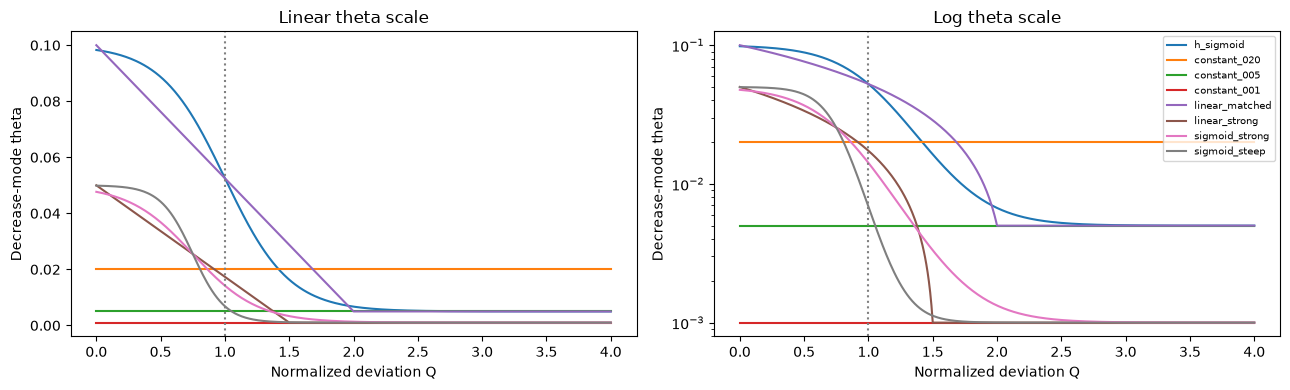

,condition,Q=0,Q=0.5,Q=1,Q=1.5,Q=2,Q=3
0,h_sigmoid,0.098291,0.088676,0.052500,0.016324,0.006709,0.005032
1,constant_020,0.020000,0.020000,0.020000,0.020000,0.020000,0.020000
2,constant_005,0.005000,0.005000,0.005000,0.005000,0.005000,0.005000
3,constant_001,0.001000,0.001000,0.001000,0.001000,0.001000,0.001000
4,linear_matched,0.100000,0.076250,0.052500,0.028750,0.005000,0.005000
5,linear_strong,0.050000,0.033667,0.017333,0.001000,0.001000,0.001000
6,sigmoid_strong,0.047676,0.036822,0.014178,0.003324,0.001328,0.001006
7,sigmoid_steep,0.049879,0.044159,0.006841,0.001121,0.001002,0.001000


In [3]:
q_grid=np.linspace(0,4,401)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for name,s in DECREASE_SCHEDULES.items():
    y=[schedule_value(q,s) for q in q_grid]
    for ax in axes:ax.plot(q_grid,y,label=name)
for ax in axes:
    ax.axvline(1,color='gray',ls=':');ax.set(xlabel='Normalized deviation Q',ylabel='Decrease-mode theta')
axes[0].set_title('Linear theta scale');axes[1].set_yscale('log');axes[1].set_title('Log theta scale')
axes[1].legend(fontsize=7);fig.tight_layout();fig.savefig(OUT/'planned_schedules.png',dpi=180);plt.show()
display(pd.DataFrame([dict(condition=name,**{f'Q={q}':schedule_value(q,s) for q in [0,.5,1,1.5,2,3]}) for name,s in DECREASE_SCHEDULES.items()]))

## Controller engine and invariants
The C02h search/commit engine is unchanged. Only the schedule evaluator supports additional function families. Tests verify probability bounds, monotonicity, matching midpoint values, exact reproduction of the prior sigmoid, and the word-boundary/checkpoint rules.

In [4]:
# Word feedback engine. Pure Python except for the supplied generator/tokenizer backend.
import math
import heapq
from collections import Counter

class IncompleteGeneration(RuntimeError):
    """Operational or boundary failure; never interpreted as exhausted alternatives."""


def first_closed_word(backend, ids, fixed_prefix):
    """Return first fully delimited alphabetic spaCy token after fixed_prefix.
    Wait for whitespace (or EOS) to stabilize tokenization of contractions and
    punctuation inside the current chunk. A model token may span several words.
    Only the first word is committed; later characters remain tentative.
    """
    text = backend.decode(tuple(ids))
    stable = text.rstrip('\ufffd')
    common = min(len(stable), len(fixed_prefix))
    if stable[:common] != fixed_prefix[:common]:
        return dict(kind='prefix_conflict', text=text)
    if len(stable) < len(fixed_prefix):
        if backend.ended(ids):
            return dict(kind='prefix_conflict', text=text)
        return dict(kind='pending', text=text)
    final = backend.ended(ids)
    if final:
        if '\ufffd' in text:
            raise IncompleteGeneration('EOS with undecodable byte sequence.')
        closed_end = len(text)
    else:
        closed_end = max((i+1 for i,c in enumerate(stable) if c.isspace()), default=0)
    if closed_end < len(fixed_prefix):
        return dict(kind='pending', text=text)
    for word, start, end in backend.word_spans(text[:closed_end]):
        if start < len(fixed_prefix) < end:
            raise IncompleteGeneration('Tokenizer changed a previously committed word boundary.')
        if start >= len(fixed_prefix):
            return dict(kind='word', word=word, start=start, end=end, text=text)
    return dict(kind='end' if final else 'pending', text=text)


def greedy_to_word(backend, ids, probabilities, fixed_prefix):
    ids, probabilities = list(ids), list(probabilities)
    while True:
        view = first_closed_word(backend, ids, fixed_prefix)
        if view['kind'] in {'word', 'end'}:
            return dict(ids=ids, probabilities=probabilities, view=view)
        if view['kind'] == 'prefix_conflict':
            raise IncompleteGeneration('Ordinary decoding changed committed text.')
        choices = backend.choices(tuple(ids), threshold=None)
        if not choices:
            raise IncompleteGeneration('No permitted next token in ordinary decoding.')
        token, probability = choices[0]
        ids.append(int(token)); probabilities.append(float(probability))


def backtrack_anchor(backend, baseline_ids, fixed_prefix):
    # Find a token boundary at or before the character boundary. If a token
    # straddles an earlier committed word and the new word, replay that token
    # while constraining its already-committed characters exactly.
    for n in range(len(baseline_ids), -1, -1):
        prefix_ids = tuple(baseline_ids[:n])
        if backend.ended(prefix_ids):
            continue
        text = backend.decode(prefix_ids)
        if '\ufffd' not in text and fixed_prefix.startswith(text):
            return n
    raise IncompleteGeneration('No valid token checkpoint for this word.')


def search_word(backend, baseline, fixed_prefix, seen, desired, theta,
                on_search=lambda event: None):
    """Best-first search over paths whose word-forming tokens have raw
    probability >= theta. Greedy boundary-only confirmation is exempt. No search-count or depth cutoff.
    Completed undesired words terminate their branch. An operational failure
    propagates rather than masquerading as 'no alternative'.
    """
    if desired not in {'increase', 'decrease'} or not 0 < theta <= 1:
        raise ValueError('Invalid search mode or probability threshold.')
    anchor = backtrack_anchor(backend, baseline['ids'], fixed_prefix)
    root = tuple(baseline['ids'][:anchor])
    heap = [(0.0, 0, (), ())]
    serial = 0; expanded = 0; completed = 0; distinct=set()
    while heap:
        negative_logp, _, suffix, probs = heapq.heappop(heap)
        ids = root + suffix
        view = first_closed_word(backend, ids, fixed_prefix)
        if view['kind'] == 'prefix_conflict':
            continue
        if view['kind'] == 'word':
            novel = view['word'].lower() not in seen
            acceptable = novel if desired == 'increase' else not novel
            completed += 1; distinct.add(view['word'].lower())
            on_search(dict(event='completed_candidate', word=view['word'], novel=novel,
                acceptable=acceptable, branch_log_probability=-negative_logp,
                branch_tokens=list(suffix), branch_probabilities=list(probs),
                expanded=expanded, frontier=len(heap)))
            if acceptable:
                return dict(ids=list(ids), probabilities=baseline['probabilities'][:anchor]+list(probs),
                    view=view, anchor=anchor, branch_tokens=list(suffix),
                    branch_probabilities=list(probs), expanded=expanded,
                    completed_candidates=completed, distinct_candidates=len(distinct), exhausted=False,
                    boundary_exempt_indices=[i for i,p in enumerate(probs) if p<theta])
            continue
        if view['kind'] == 'end':
            continue
        # Full distribution is filtered ONLY by the declared probability threshold
        # and the fixed exclusion of non-EOS protocol/control tokens.
        choices = backend.choices(ids, threshold=theta)
        # Boundary-only confirmation may follow the ordinary greedy token below
        # theta. It must close an already-spelled word without changing its letters.
        greedy = backend.choices(ids, threshold=None)
        exempt_token=None
        if greedy and greedy[0][1]<theta:
            token,p=greedy[0]
            before_text=backend.decode(ids)
            after_view=first_closed_word(backend, ids+(int(token),), fixed_prefix)
            boundary_only=(after_view['kind']=='word'
                and after_view['end']<=len(before_text)
                and before_text[:after_view['end']]==after_view['text'][:after_view['end']]
                and '\ufffd' not in before_text)
            if boundary_only:
                choices=choices+[(token,p)]; exempt_token=token
        on_search(dict(event='eligibility',theta=theta,
            eligible_lexical_or_boundary_tokens=len(choices)-int(exempt_token is not None),
            greedy_probability=greedy[0][1] if greedy else None,
            greedy_below_threshold=bool(greedy and greedy[0][1]<theta),
            boundary_exemption=exempt_token is not None))
        expanded += 1
        for token, probability in choices:
            assert probability >= theta or token==exempt_token
            serial += 1
            heapq.heappush(heap, (negative_logp-math.log(probability), serial,
                suffix+(int(token),), probs+(float(probability),)))
        on_search(dict(event='expanded', expanded=expanded, frontier=len(heap),
                       eligible_children=len(choices)))
    return dict(exhausted=True, expanded=expanded, completed_candidates=completed, distinct_candidates=len(distinct), anchor=anchor)


def initial_state(condition):
    return dict(condition=condition, ids=[], probabilities=[], committed_text='',
                words=[], mode='normal', trajectory=[], finished=False, status='ready',
                search_attempts=0, replacements=0, fallbacks=0)


def run_feedback(backend, state, curve, warmup_words, schedules,
                 checkpoint=lambda state: None, on_search=lambda event: None,
                 on_status=lambda state: None):
    # state is only mutated after a complete word is selected. During search it
    # stays at the last valid checkpoint; interruption cannot commit half a word.
    try:
        while not state['finished']:
            W = len(state['words']); seen = set(state['words']); V = len(seen)
            ref=reference_at(curve,W)
            mode=adaptive_mode(state['mode'],V,W,warmup_words,ref)
            if state['condition'] == 'baseline': mode = 'normal'
            theta,Q=adaptive_theta(mode,V/W if W else 0.,W,ref,schedules)
            ordinary = greedy_to_word(backend, state['ids'], state['probabilities'], state['committed_text'])
            if ordinary['view']['kind'] == 'end':
                state.update(ids=ordinary['ids'], probabilities=ordinary['probabilities'],
                    committed_text=ordinary['view']['text'], finished=True, status='completed_eos')
                actual = [w.lower() for w,_,_ in backend.word_spans(state['committed_text'])]
                if actual != state['words']:
                    state['finished'] = False
                    raise IncompleteGeneration('Final tokenizer counts differ from the committed-word ledger.')
                state.pop('last_error', None)
                checkpoint(state); on_status(state); break
            original_word = ordinary['view']['word']
            original_novel = original_word.lower() not in seen
            conflict = (mode == 'increase' and not original_novel) or (mode == 'decrease' and original_novel)
            selected = ordinary; action = 'ordinary'; info = {}
            if conflict:
                # Freeze all preceding text, including intervening punctuation.
                fixed_prefix = ordinary['view']['text'][:ordinary['view']['start']]
                info = search_word(backend, ordinary, fixed_prefix, seen, mode, theta, on_search)
                if info['exhausted']:
                    action = 'fallback_exhausted'
                else:
                    selected = info; action = 'backtracked'
            word = selected['view']['word']; novel = word.lower() not in seen
            if action == 'backtracked':
                assert novel == (mode == 'increase')
                assert all(p>=theta or i in info['boundary_exempt_indices']
                    for i,p in enumerate(info['branch_probabilities']))
            # No earlier committed text can change, including model-token straddles.
            new_prefix = selected['view']['text'][:selected['view']['end']]
            assert new_prefix.startswith(state['committed_text'])
            if conflict: assert new_prefix.startswith(fixed_prefix)
            entry = dict(word_index=W+1, word=word, original_word=original_word,
                original_novel=original_novel, chosen_novel=novel, action=action,
                mode_before=mode, theta=theta, Q=Q, reference_before=ref,
                reference_after=reference_at(curve,W+1),
                boundary_exempt_indices=info.get('boundary_exempt_indices',[]),
                distinct_candidates=info.get('distinct_candidates',0), W_before=W, V_before=V, k_before=V/W if W else None,
                W_after=W+1, V_after=V+int(novel), k_after=(V+int(novel))/(W+1),
                search_expanded=info.get('expanded',0),
                completed_candidates=info.get('completed_candidates',0),
                branch_tokens=info.get('branch_tokens',[]),
                branch_probabilities=info.get('branch_probabilities',[]))
            state.update(ids=selected['ids'], probabilities=selected['probabilities'],
                         committed_text=new_prefix, mode=mode, status='running')
            state['words'].append(word.lower()); state['trajectory'].append(entry)
            state['search_attempts'] += int(conflict)
            state['replacements'] += int(action == 'backtracked')
            state['fallbacks'] += int(action == 'fallback_exhausted')
            checkpoint(state); on_status(state)
    except BaseException as exc:
        state['finished'] = False
        state['status'] = 'incomplete_interrupted' if isinstance(exc,KeyboardInterrupt) else 'incomplete_operational'
        state['last_error'] = type(exc).__name__ + ': ' + str(exc)
        checkpoint(state)
        raise
    return state

In [5]:
import re


class Toy:
    pieces = {0:'UNI',1:'QUE',2:'COM',3:'PARE',4:'MON',5:' ',6:''}
    def decode(self,ids): return ''.join(self.pieces[i] for i in ids)
    def ended(self,ids): return bool(ids) and ids[-1]==6
    def word_spans(self,text): return [(m.group(),m.start(),m.end()) for m in re.finditer('[A-Za-z]+',text)]
    def choices(self,ids,threshold=None):
        if not ids: c=[(0,.6),(2,.4)]
        elif ids[-1]==0: c=[(1,.99)]
        elif ids[-1]==2: c=[(3,.8),(4,.2)]
        elif ids[-1] in (1,3,4): c=[(5,1.)]
        else: c=[(6,1.)]
        return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]



S={m:dict(minimum=.005,maximum=.1,slope=4.,midpoint=1.) for m in ['increase','decrease']}
r=dict(supported=True,H_h30=.2,H_h10=.4,H_median=.5,H_a10=.6)
def run_tests():
    curve=prefix_curve([['a','b','a'],['x','x']],2)
    assert curve['1']['H_h10']==1 and curve['2']['reference_n']==2
    assert not curve['3']['supported'] and not reference_at(curve,4)['supported']
    assert adaptive_mode('normal',1,1,1,curve['1'])=='normal'
    assert adaptive_mode('normal',7,10,2,r)=='decrease'
    assert adaptive_mode('decrease',5,10,2,r)=='decrease'
    assert adaptive_mode('decrease',4,10,2,r)=='normal'
    assert adaptive_mode('normal',1,10,2,r)=='increase'
    assert adaptive_mode('increase',3,10,2,r)=='increase'
    assert adaptive_mode('increase',4,10,2,r)=='normal'
    assert adaptive_mode('decrease',8,10,2,dict(supported=False))=='unsupported'
    for mode,ks in [('decrease',[.4,.6,.9]),('increase',[.4,.2,.01])]:
        ts=[adaptive_theta(mode,k,100,r,S)[0] for k in ks]
        assert ts[0]>ts[1]>ts[2]>0
    deg=dict(supported=True,H_h30=.5,H_h10=.5,H_median=.5,H_a10=.5)
    assert math.isfinite(adaptive_theta('decrease',.7,10,deg,S)[0])
    # Original UNIQUE/COMPARE/COMMON example is unchanged.
    b=Toy();o=greedy_to_word(b,[],[],'')
    assert search_word(b,o,'',{'common'},'decrease',.1)['view']['word']=='COMMON'
    assert search_word(b,o,'',{'common'},'decrease',.3)['exhausted']
    # Exempt a low-probability greedy boundary, never a low-probability letter.
    class Boundary(Toy):
        def choices(self,ids,threshold=None):
            c=[(5,.02)] if ids and ids[-1] in [1,3,4] else super().choices(ids,None if threshold is None else 0.)
            return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]
    b=Boundary();o=greedy_to_word(b,[],[],'')
    found=search_word(b,o,'',{'common'},'decrease',.1)
    assert found['view']['word']=='COMMON' and found['boundary_exempt_indices']
    class LowLetter(Toy):
        def choices(self,ids,threshold=None):
            c=[(4,.02)] if ids and ids[-1]==2 else super().choices(ids,None if threshold is None else 0.)
            return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]
    b=LowLetter();o=greedy_to_word(b,[],[],'')
    assert search_word(b,o,'',{'common'},'decrease',.1)['exhausted']
    class Sentence(Toy):
        pieces={7:'common ',**Toy.pieces}
        def choices(self,ids,threshold=None):
            c=[(7,1.)] if not ids else [(0,.6),(2,.4)] if ids[-1]==7 else None
            if c is None:return super().choices(ids,threshold)
            return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]
    fixed={str(w):dict(r,W=w,reference_n=30) for w in range(1,10)}
    s=run_feedback(Sentence(),initial_state('controlled'),fixed,1,S)
    assert s['finished'] and s['words']==['common','common']
    assert s['trajectory'][0]['theta'] is None and s['trajectory'][1]['theta'] is not None
    class Broken(Sentence):
        def choices(self,ids,threshold=None):
            if threshold is not None:raise IncompleteGeneration('test interruption')
            return super().choices(ids,threshold)
    s=initial_state('controlled')
    try:run_feedback(Broken(),s,fixed,1,S)
    except IncompleteGeneration:pass
    assert s['status']=='incomplete_operational' and s['words']==['common'] and s['fallbacks']==0
    run_feedback(Sentence(),s,fixed,1,S)
    assert s['finished'] and 'last_error' not in s
    s=run_feedback(Sentence(),initial_state('controlled'),{},1,S)
    assert s['words']==['common','unique'] and s['trajectory'][1]['mode_before']=='unsupported'
    rows=[dict(W_after=i+1,k_after=k,reference_after=r) for i,k in enumerate([.5,.7,.8,.5,.1])]
    m=trajectory_metrics(rows,1)
    assert m['supported_words']==4 and m['longest_outside_run']==2 and m['fraction_in_band']==.25
    shifted=dict(supported=True,H_h30=.4,H_h10=.6,H_median=.7,H_a10=.8)
    assert adaptive_mode('decrease',5,10,2,shifted)=='normal'
    class Straddle(Toy):
        pieces={0:'OLD UNI',1:'QUE ',2:'OLD COM',3:'PARE ',4:'MON ',6:''}
        def choices(self,ids,threshold=None):
            c=[(0,.6),(2,.4)] if not ids else [(1,1.)] if ids[-1]==0 else [(3,.8),(4,.2)] if ids[-1]==2 else [(6,1.)]
            return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]
    b=Straddle();o=greedy_to_word(b,[],[],'OLD ')
    chosen=search_word(b,o,'OLD ',{'old','common'},'decrease',.1)
    assert chosen['view']['word']=='COMMON' and chosen['view']['text'].startswith('OLD ')
    class Long(Toy):
        pieces={0:'a',5:' ',6:''}
        def choices(self,ids,threshold=None):
            return [(0,1.)] if len(ids)<100 else [(5,1.)] if len(ids)==100 else [(6,1.)]
    b=Long();o=greedy_to_word(b,[],[],'')
    assert len(search_word(b,o,'',set(),'increase',.5)['view']['word'])==100
    print('Adaptive tests passed: prefix support, moving hysteresis, sigmoid direction, degenerate quantiles, lexical vs boundary eligibility, fallback, checkpoint/resume, unsupported continuation, and trajectory metrics.')


run_tests()
for spec in DECREASE_SCHEDULES.values():
    vals=[schedule_value(q,spec) for q in np.linspace(0,10,1001)]
    assert all(0<v<=1 for v in vals)
    assert all(a>=b for a,b in zip(vals,vals[1:]))
for q in [0,.1,1,2,1000]:
    spec=DECREASE_SCHEDULES['h_sigmoid']
    z=4*(q-1)
    original=.005+.095*(math.exp(-z)/(1+math.exp(-z)) if z>=0 else 1/(1+math.exp(z)))
    assert schedule_value(q,spec)==original
assert np.isclose(schedule_value(1,DECREASE_SCHEDULES['linear_matched']),schedule_value(1,DECREASE_SCHEDULES['h_sigmoid']))
for name in ['sigmoid_strong','sigmoid_steep']:
    assert np.isclose(schedule_value(.75,DECREASE_SCHEDULES['linear_strong']),schedule_value(.75,DECREASE_SCHEDULES[name]))
print('Schedule-family invariants passed.')

Adaptive tests passed: prefix support, moving hysteresis, sigmoid direction, degenerate quantiles, lexical vs boundary eligibility, fallback, checkpoint/resume, unsupported continuation, and trajectory metrics.
Schedule-family invariants passed.


## Load the pinned generator and freeze this sweep
The model is loaded once. Previous results are eligible for reuse only when model revision, tokenizer, versions, device/dtype, spaCy, context capacity, and exact prompt token IDs agree. Reusing results saves computation; all provenance is retained. Changing any schedule requires a new output directory.

In [6]:
torch.manual_seed(0)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = (torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
         else torch.float16 if DEVICE=='cuda' else torch.float32)
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=TOKENIZER_REVISION)
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,revision=MODEL_REVISION,dtype=DTYPE).to(DEVICE).eval()
EOS_IDS=model.generation_config.eos_token_id
EOS_IDS=set(EOS_IDS if isinstance(EOS_IDS,(list,tuple)) else [EOS_IDS])
EOS_IDS.discard(None)
if tokenizer.eos_token_id is not None: EOS_IDS.add(tokenizer.eos_token_id)
assert EOS_IDS
FORBIDDEN_SPECIAL=set(tokenizer.all_special_ids)-EOS_IDS
CONTEXT_SIZE=int(model.config.max_position_embeddings)
KEEP_LAST='logits_to_keep' in inspect.signature(model.forward).parameters

PROMPT_VERSION='meaning-preserving-rewrite-v1'
def messages_for(case):
    return [dict(role='system',content='Rewrite the supplied passage. Preserve its meaning, facts, names, numbers, and genre. Use approximately the same length. Return only the rewritten passage, with no explanation or preamble.'),
            dict(role='user',content=case['original'])]

class LocalBackend:
    def __init__(self,prompt_ids): self.prompt_ids=list(prompt_ids)
    def decode(self,ids):
        return tokenizer.decode(list(ids),skip_special_tokens=True,clean_up_tokenization_spaces=False)
    def ended(self,ids): return bool(ids) and ids[-1] in EOS_IDS
    def word_spans(self,text): return word_spans(text)
    def choices(self,ids,threshold=None):
        full=self.prompt_ids+list(ids)
        if len(full)>=CONTEXT_SIZE:
            raise IncompleteGeneration(f'Model context capacity reached ({CONTEXT_SIZE}); search or generation is incomplete.')
        x=torch.tensor([full],dtype=torch.long,device=DEVICE)
        with torch.inference_mode():
            kwargs={'logits_to_keep':1} if KEEP_LAST else {}
            output=model(input_ids=x,attention_mask=torch.ones_like(x),use_cache=False,**kwargs)
            probabilities=torch.softmax(output.logits[0,-1].float(),dim=-1)
            if not torch.isfinite(probabilities).all().item():
                raise IncompleteGeneration('Non-finite next-token distribution.')
            valid=probabilities.clone()
            for i in FORBIDDEN_SPECIAL:
                if i<len(valid): valid[i]=-1
            if threshold is None:
                ids_out=[int(valid.argmax().item())]
            else:
                ids_out=torch.nonzero(valid>=threshold,as_tuple=False).flatten().tolist()
            pairs=[(int(i),float(probabilities[i].item())) for i in ids_out]
        return sorted(pairs,key=lambda pair:(-pair[1],pair[0]))

from collections.abc import Mapping
from numbers import Integral

def normalized_prompt_ids(encoded):
    if isinstance(encoded,Mapping): encoded=encoded['input_ids']
    if hasattr(encoded,'tolist'): encoded=encoded.tolist()
    if isinstance(encoded,(list,tuple)) and len(encoded)==1:
        first=encoded[0]
        if hasattr(first,'tolist'): first=first.tolist()
        if isinstance(first,(list,tuple)): encoded=first
    if not isinstance(encoded,(list,tuple)) or not encoded:
        raise TypeError('Expected nonempty token IDs.')
    if not all(isinstance(t,Integral) and not isinstance(t,bool) for t in encoded):
        raise TypeError('Expected one flat integer token sequence.')
    ids=[int(t) for t in encoded]
    assert all(0<=t<model.config.vocab_size for t in ids)
    return ids

for c in cases:
    ids=normalized_prompt_ids(tokenizer.apply_chat_template(messages_for(c),tokenize=True,
        add_generation_prompt=True,return_dict=True,return_tensors=None))
    assert ids==c['prompt_ids'],'Prompt/tokenizer changed from C02h.'

versions={p:metadata.version(p) for p in ['torch','transformers','spacy','numpy','pandas']}
runtime=dict(model=MODEL_ID,resolved_revision=getattr(model.config,'_commit_hash',None),
    tokenizer_revision=tokenizer.init_kwargs.get('_commit_hash'),versions=versions,
    device=DEVICE,dtype=str(DTYPE),spacy_meta=nlp.meta,context_size=CONTEXT_SIZE,prompt_version=PROMPT_VERSION)
for key,value in runtime.items():
    assert digest(value)==digest(previous_contract[key]),f'C02h environment mismatch: {key}. Restore the previous environment.'
contract=dict(previous_contract_hash=PREVIOUS_HASH,runtime=runtime,cases=cases,references=references,
    conditions=CONDITION_ORDER,schedules=SCHEDULES,warmup_fraction=WARMUP_FRACTION,
    minimum_prefix_support=MIN_PREFIX_SUPPORT,boundary_policy=previous_contract['boundary_policy'],
    implementation_sha256=IMPLEMENTATION_SHA256)
CONTRACT_HASH=digest(contract)
contract_path=OUT/'frozen_contract.json'
if contract_path.exists():
    assert digest(json.loads(contract_path.read_text()))==CONTRACT_HASH,'Sweep changed: choose a new OUT directory.'
else:write_json(contract_path,contract)
print('Sweep contract:',CONTRACT_HASH)

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 7305.79it/s]


Sweep contract: 45cf02148deac7a94d6695e87003da4cd6625104f7b6ebf54cc38f175fa38258


## Generate all planned comparisons
One status display updates in place. Each condition/case has its own state and JSONL search audit. Re-running resumes unfinished runs. Operational failures are recorded and the remaining cases continue; a user interrupt stops the cell. Incomplete cases remain in all status tables. Logs record observed wall time (including unsuccessful attempts), but imported runs have unknown timing.

`RUN_CONDITIONS` can select which conditions to execute when resuming; this is task scheduling, not a search or intervention budget. Reports retain the complete planned comparison.

In [8]:
import time
import html
from IPython.display import display, HTML

# Reuse the already-computed highest-probability eligible token.
# Candidate eligibility and search order remain unchanged.
_original_choices = getattr(
    LocalBackend.choices, "_original_choices", LocalBackend.choices
)

def choices_without_duplicate_forward(self, ids, threshold=None):
    key = tuple(ids)
    cached = getattr(self, "_last_threshold_choices", None)

    if threshold is None and cached is not None:
        cached_key, cached_choices = cached
        if cached_key == key and cached_choices:
            return cached_choices[:1]

    result = _original_choices(self, ids, threshold=threshold)

    if threshold is not None:
        self._last_threshold_choices = (key, result)
    else:
        self._last_threshold_choices = None

    return result

choices_without_duplicate_forward._original_choices = _original_choices
LocalBackend.choices = choices_without_duplicate_forward


# Add a separate display that updates while a single word is being searched.
_original_feedback = getattr(
    run_feedback, "_original_feedback", run_feedback
)

def monitored_feedback(
    backend, state, curve, warmup_words, schedules,
    checkpoint=lambda state: None,
    on_search=lambda event: None,
    on_status=lambda state: None,
):
    handle = display(HTML("Search monitor ready."), display_id=True)
    monitor = {
        "word": None, "started": None, "last_update": 0.0,
        "expanded": 0, "frontier": 0, "completed": 0, "theta": None,
    }

    def search_progress(event):
        on_search(event)  # Preserve the existing audit log.
        now = time.monotonic()
        word_index = len(state["words"]) + 1

        if monitor["word"] != word_index:
            monitor.update(
                word=word_index, started=now, last_update=0.0,
                expanded=0, frontier=0, completed=0, theta=None,
            )

        for key in ("expanded", "frontier", "theta"):
            if key in event:
                monitor[key] = event[key]

        if event["event"] == "completed_candidate":
            monitor["completed"] += 1

        if now - monitor["last_update"] >= 1.0:
            elapsed = now - monitor["started"]
            rate = monitor["expanded"] / max(elapsed, 1e-9)
            theta = monitor["theta"]
            theta_text = f"{theta:.6f}" if theta is not None else "—"

            message = (
                f"{state['condition']} | searching word {word_index} "
                f"| θ={theta_text} | elapsed={elapsed:.0f}s "
                f"| expanded={monitor['expanded']:,} "
                f"| queued={monitor['frontier']:,} "
                f"| completed candidates={monitor['completed']:,} "
                f"| {rate:.2f} expansions/s"
            )
            handle.update(HTML(html.escape(message)))
            monitor["last_update"] = now

    try:
        return _original_feedback(
            backend, state, curve, warmup_words, schedules,
            checkpoint, search_progress, on_status,
        )
    finally:
        handle.update(HTML(html.escape(
            f"{state['condition']} | {state['status']} "
            f"| committed words={len(state['words'])}"
        )))

monitored_feedback._original_feedback = _original_feedback
run_feedback = monitored_feedback

print("Patched. Rerun the generation cell to resume.")

Patched. Rerun the generation cell to resume.


In [10]:
MAX_WORD_CANDIDATES = 500

# Preserve the underlying functions when this patch is rerun.
_uncapped_search = getattr(search_word, "_uncapped_search", search_word)
_previous_feedback = getattr(run_feedback, "_before_candidate_cap", run_feedback)
_pending_cap = [None]

class _CandidateLimitReached(Exception):
    pass

def capped_search(
    backend, baseline, fixed_prefix, seen, desired, theta,
    on_search=lambda event: None,
):
    _pending_cap[0] = None
    completed = 0
    expanded = 0

    def audit(event):
        nonlocal completed, expanded
        expanded = event.get("expanded", expanded)
        on_search(event)

        if event["event"] == "completed_candidate":
            completed += 1

            # Accept candidate 500 if it qualifies.
            if completed >= MAX_WORD_CANDIDATES and not event["acceptable"]:
                raise _CandidateLimitReached

    try:
        return _uncapped_search(
            backend, baseline, fixed_prefix, seen, desired, theta, audit
        )
    except _CandidateLimitReached:
        info = {
            "stop_reason": "candidate_limit",
            "candidate_limit": MAX_WORD_CANDIDATES,
            "completed_candidates": completed,
            "expanded": expanded,
        }
        _pending_cap[0] = info
        on_search(dict(event="candidate_limit_fallback", **info))

        # Existing engine uses this flag to restore the ordinary word.
        # The checkpoint wrapper below records the actual stopping reason.
        return dict(
            exhausted=True,
            anchor=backtrack_anchor(backend, baseline["ids"], fixed_prefix),
            **info,
        )

capped_search._uncapped_search = _uncapped_search
search_word = capped_search


def feedback_with_candidate_cap(
    backend, state, curve, warmup_words, schedules,
    checkpoint=lambda state: None,
    on_search=lambda event: None,
    on_status=lambda state: None,
):
    _pending_cap[0] = None
    if not state["finished"]:
        state["status"] = "running"

    def annotated_checkpoint(s):
        if _pending_cap[0] is not None and s["trajectory"]:
            step = s["trajectory"][-1]
            if step["action"] == "fallback_exhausted":
                # Keep the legacy action for existing aggregate code, but
                # explicitly distinguish cutoff from genuine exhaustion.
                step["fallback_reason"] = "candidate_limit"
                step["search_exhausted"] = False
                step["candidate_limit"] = MAX_WORD_CANDIDATES
                _pending_cap[0] = None

        checkpoint(s)

    return _previous_feedback(
        backend, state, curve, warmup_words, schedules,
        annotated_checkpoint, on_search, on_status,
    )

feedback_with_candidate_cap._before_candidate_cap = _previous_feedback
run_feedback = feedback_with_candidate_cap

print("Installed: 500 completed candidate paths per word, then ordinary fallback.")

Installed: 500 completed candidate paths per word, then ordinary fallback.


In [11]:
status_handle=display(HTML('Ready'),display_id=True);last_display=[0.]

def validate_finished_state(case,state):
    assert state['finished'] and state['status']=='completed_eos'
    assert backend.decode(tuple(state['ids']))==state['committed_text']
    words=[w.lower() for w,_,_ in word_spans(state['committed_text'])]
    assert words==state['words']
    assert len(state['trajectory'])==len(words)
    for step in state['trajectory']:
        assert digest(step['reference_after'])==digest(reference_at(case['curve'],step['W_after']))

for case in cases:
    for condition in RUN_CONDITIONS:
        case_id=case['case_id'];folder=OUT/case_id/condition;folder.mkdir(parents=True,exist_ok=True)
        path=folder/'state.json';backend=LocalBackend(case['prompt_ids'])
        if path.exists():
            payload=json.loads(path.read_text());assert payload['contract_hash']==CONTRACT_HASH
            state=payload['state'];provenance=payload.get('provenance',{})
        else:
            state=initial_state(condition);provenance=dict(kind='generated_here')
            old_condition={'baseline':'baseline','h_sigmoid':'controlled'}.get(condition)
            old_path=PREVIOUS_OUT/case_id/str(old_condition)/'state.json'
            if REUSE_C02H and old_condition and old_path.exists():
                prior_bytes=old_path.read_bytes();prior=json.loads(prior_bytes)
                assert prior['contract_hash']==PREVIOUS_HASH
                if prior['state']['finished'] and prior['state']['status']=='completed_eos':
                    state=copy.deepcopy(prior['state']);state['condition']=condition
                    validate_finished_state(case,state)
                    provenance=dict(kind='imported_C02h',source=str(old_path),source_sha256=hashlib.sha256(prior_bytes).hexdigest())
                    write_json(path,dict(contract_hash=CONTRACT_HASH,state=state,provenance=provenance))
        if state['finished']:
            validate_finished_state(case,state)
            continue
        attempt_id=uuid.uuid4().hex;started=time.monotonic()
        state['observed_wall_seconds']=state.get('observed_wall_seconds',0.)
        prior_seconds=state['observed_wall_seconds']
        def checkpoint(s):
            s['observed_wall_seconds']=prior_seconds+time.monotonic()-started
            write_json(path,dict(contract_hash=CONTRACT_HASH,state=s,provenance=provenance))
        def status(s,force=False):
            now=time.monotonic()
            if not force and now-last_display[0]<.3:return
            last_display[0]=now;W=len(s['words']);k=len(set(s['words']))/W if W else 0.
            status_handle.update(HTML(html.escape(f"{case_id} | {condition} | {s['status']} | words={W} | k={k:.4f} | mode={s['mode']} | replacements={s['replacements']}")))
        try:
            with (folder/'search_audit.jsonl').open('a',buffering=1) as audit:
                def search_log(event):
                    audit.write(json.dumps(dict(attempt_id=attempt_id,word_index=len(state['words'])+1,**event),allow_nan=False)+'\n');status(state)
                schedules=SCHEDULES.get(condition,SCHEDULES['h_sigmoid'])
                run_feedback(backend,state,case['curve'],case['warmup_words'],schedules,checkpoint,search_log,status)
            validate_finished_state(case,state)
        except KeyboardInterrupt:
            status(state,True);print('Interrupted; checkpoint retained:',path);raise
        except Exception as exc:
            if state['finished']:
                state['finished']=False;state['status']='incomplete_validation'
                state['last_error']=type(exc).__name__+': '+str(exc);checkpoint(state)
            status(state,True);print('Incomplete:',case_id,condition,type(exc).__name__,str(exc))
            if torch.cuda.is_available():torch.cuda.empty_cache()
            continue
        status(state,True)
        (folder/'generated.txt').write_text(state['committed_text'])
        pd.DataFrame(state['trajectory']).to_csv(folder/'word_trajectory.csv',index=False)
print('Execution pass finished. Inspect completion status below before comparing conditions.')

Execution pass finished. Inspect completion status below before comparing conditions.


## Tracking metrics and shared-position comparisons
The primary table uses one common word horizon per case across **all nine planned conditions**, only when all reach EOS. It also stops at the last human-supported position. Pairwise comparisons use baseline/variant shared positions and may cover different horizons. Both mean above-band error (desired reduction) and mean below-band error (overshoot) are reported. Full-text metrics retain each output's own length and support coverage. No confidence intervals treat dependent word positions as independent samples.

condition,baseline,h_sigmoid,constant_020,constant_005,constant_001,linear_matched,linear_strong,sigmoid_strong,sigmoid_steep
case_id,,,,,,,,,
raid_micro_01,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos
raid_micro_02,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos
raid_micro_03,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos
raid_micro_04,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos
raid_micro_05,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos
raid_micro_06,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos
raid_micro_07,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos
raid_micro_08,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos,completed_eos


PRIMARY: same word positions across all variants; equal weight per case. Negative error change is favorable.


,n_cases,n_evaluable_cases,mean_horizon,mean_in_band,mean_above,mean_below,mean_distance,mean_longest_excursion
condition,,,,,,,,
baseline,8,8,167.5,0.345949,0.034154,0.006735,0.040889,65.250
h_sigmoid,8,8,167.5,0.627751,0.005409,0.002569,0.007978,21.625
constant_020,8,8,167.5,0.624174,0.010121,0.003110,0.013231,28.500
constant_005,8,8,167.5,0.764404,0.002881,0.003079,0.005960,17.125
constant_001,8,8,167.5,0.791681,0.001381,0.003057,0.004438,13.375
linear_matched,8,8,167.5,0.568944,0.008609,0.002569,0.011178,31.125
linear_strong,8,8,167.5,0.734880,0.002368,0.003398,0.005766,16.875
sigmoid_strong,8,8,167.5,0.741151,0.002332,0.003096,0.005428,16.500
sigmoid_steep,8,8,167.5,0.756698,0.001505,0.003407,0.004912,16.875


condition,baseline,h_sigmoid,constant_020,constant_005,constant_001,linear_matched,linear_strong,sigmoid_strong,sigmoid_steep
case_id,,,,,,,,,
raid_micro_01,0.0071,0.0055,0.0049,0.0018,0.0005,0.0055,0.0010,0.0027,0.0005
raid_micro_02,0.0098,0.0098,0.0050,0.0026,0.0010,0.0098,0.0044,0.0044,0.0014
raid_micro_03,0.0812,0.0041,0.0019,0.0014,0.0018,0.0075,0.0019,0.0019,0.0018
raid_micro_04,0.0031,0.0011,0.0010,0.0001,0.0001,0.0011,0.0005,0.0003,0.0001
raid_micro_05,0.0281,0.0061,0.0098,0.0063,0.0026,0.0061,0.0033,0.0033,0.0026
raid_micro_06,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
raid_micro_07,0.1440,0.0154,0.0573,0.0103,0.0045,0.0377,0.0067,0.0057,0.0050
raid_micro_08,0.0000,0.0012,0.0012,0.0005,0.0005,0.0012,0.0012,0.0004,0.0005


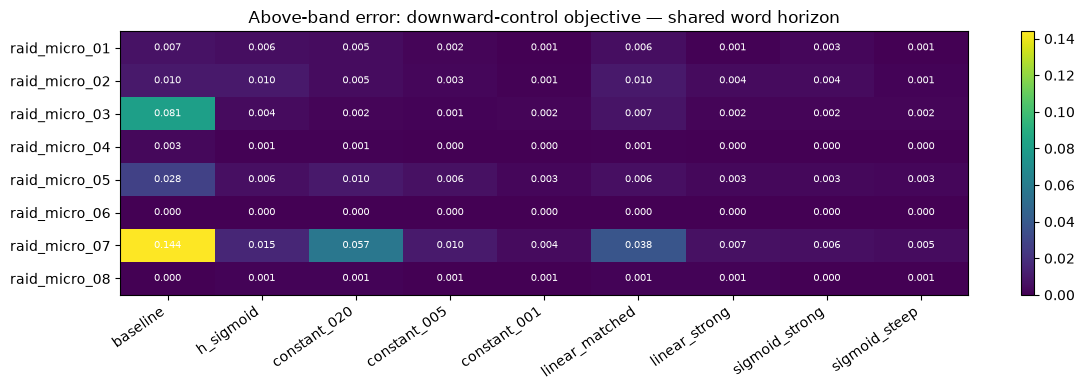

condition,baseline,h_sigmoid,constant_020,constant_005,constant_001,linear_matched,linear_strong,sigmoid_strong,sigmoid_steep
case_id,,,,,,,,,
raid_micro_01,0.0000,0.0000,0.0002,0.0000,0.0001,0.0000,0.0000,0.0000,0.0002
raid_micro_02,0.0013,0.0013,0.0054,0.0054,0.0027,0.0013,0.0054,0.0054,0.0054
raid_micro_03,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
raid_micro_04,0.0101,0.0059,0.0059,0.0059,0.0059,0.0059,0.0059,0.0059,0.0059
raid_micro_05,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0001,0.0001,0.0000
raid_micro_06,0.0164,0.0029,0.0029,0.0029,0.0029,0.0029,0.0029,0.0029,0.0029
raid_micro_07,0.0000,0.0000,0.0000,0.0000,0.0025,0.0000,0.0025,0.0000,0.0025
raid_micro_08,0.0261,0.0105,0.0105,0.0105,0.0105,0.0105,0.0105,0.0105,0.0105


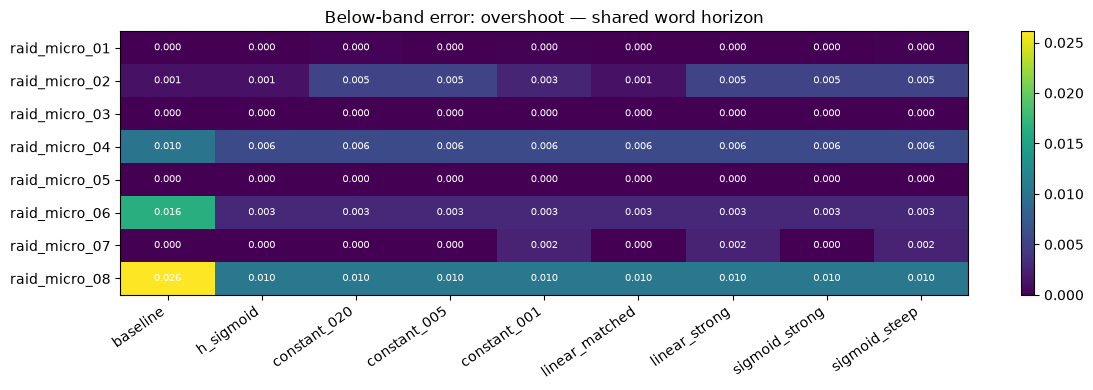

condition,baseline,h_sigmoid,constant_020,constant_005,constant_001,linear_matched,linear_strong,sigmoid_strong,sigmoid_steep
case_id,,,,,,,,,
raid_micro_01,0.6746,0.5680,0.6805,0.8580,0.9231,0.5680,0.9053,0.7751,0.9172
raid_micro_02,0.4508,0.4508,0.5544,0.5803,0.7927,0.4508,0.5751,0.5751,0.6218
raid_micro_03,0.0702,0.7018,0.8772,0.9123,0.8947,0.6316,0.8772,0.8772,0.8947
raid_micro_04,0.4419,0.6279,0.6512,0.7674,0.7674,0.6453,0.6919,0.7035,0.7616
raid_micro_05,0.1795,0.9060,0.8803,0.8974,0.9316,0.9060,0.8974,0.8974,0.9231
raid_micro_06,0.2110,0.6101,0.6101,0.6101,0.6101,0.6101,0.6101,0.6101,0.6101
raid_micro_07,0.0000,0.4177,0.0000,0.7089,0.6329,0.0000,0.5823,0.6962,0.5443
raid_micro_08,0.7397,0.7397,0.7397,0.7808,0.7808,0.7397,0.7397,0.7945,0.7808


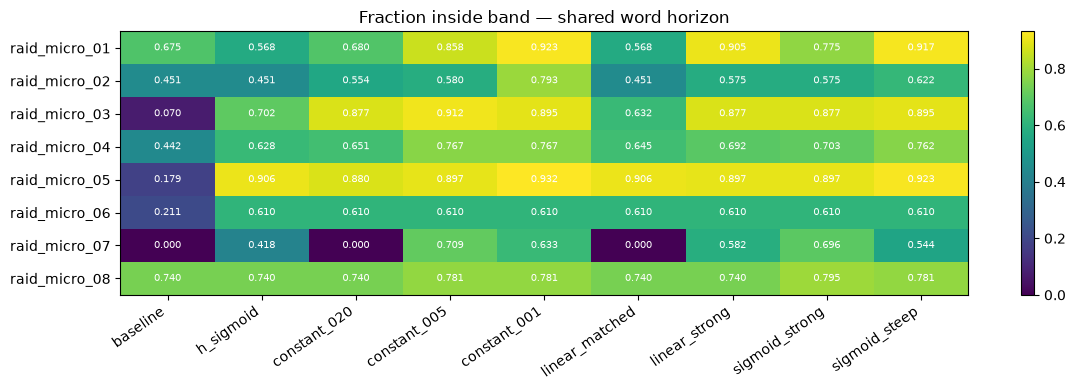

PAIRWISE: different pairs may cover different word horizons; inspect per-case CSV.


,n_cases,delta_in_band,delta_above,delta_below,delta_distance
condition,,,,,
h_sigmoid,8,0.286355,-0.028752,-0.003953,-0.032705
constant_020,8,0.273359,-0.023966,-0.003425,-0.027391
constant_005,8,0.401505,-0.030873,-0.003576,-0.034449
constant_001,8,0.417339,-0.032316,-0.003407,-0.035723
linear_matched,8,0.217740,-0.025388,-0.004002,-0.029390
linear_strong,8,0.389668,-0.031822,-0.003261,-0.035082
sigmoid_strong,8,0.399230,-0.031973,-0.003602,-0.035575
sigmoid_steep,8,0.404895,-0.032511,-0.003112,-0.035623


Full-text metrics (different lengths):


,case_id,condition,status,complete,scope,W,W_ref,length_ratio,k,endpoint_supported,...,observed_wall_seconds,observed_words,supported_words,reference_coverage,fraction_in_band,mean_above_band,mean_below_band,mean_band_distance,maximum_band_distance,longest_outside_run
0,raid_micro_01,baseline,completed_eos,True,complete_text,256,249,1.028112,0.500000,False,...,NaN,218,212,0.972477,0.740566,0.005644,0.000000,0.005644,0.039216,44
1,raid_micro_01,h_sigmoid,completed_eos,True,complete_text,219,249,0.879518,0.534247,True,...,NaN,181,181,1.000000,0.591160,0.005185,0.000000,0.005185,0.029703,16
2,raid_micro_01,constant_020,completed_eos,True,complete_text,255,249,1.024096,0.501961,False,...,68.667122,217,212,0.976959,0.745283,0.003892,0.000196,0.004088,0.034667,22
3,raid_micro_01,constant_005,completed_eos,True,complete_text,217,249,0.871486,0.534562,True,...,65.631270,179,179,1.000000,0.865922,0.001737,0.000000,0.001737,0.027027,6
4,raid_micro_01,constant_001,completed_eos,True,complete_text,271,249,1.088353,0.487085,False,...,82.515458,233,212,0.909871,0.938679,0.000437,0.000091,0.000528,0.018182,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,raid_micro_08,constant_001,completed_eos,True,complete_text,90,111,0.810811,0.677778,True,...,8.129082,73,73,1.000000,0.780822,0.000539,0.010476,0.011014,0.166667,7
68,raid_micro_08,linear_matched,completed_eos,True,complete_text,91,111,0.819820,0.670330,True,...,10.183067,74,74,1.000000,0.743243,0.001142,0.010334,0.011476,0.166667,7
69,raid_micro_08,linear_strong,completed_eos,True,complete_text,92,111,0.828829,0.663043,True,...,12.644207,75,75,1.000000,0.746667,0.001126,0.010196,0.011323,0.166667,7
70,raid_micro_08,sigmoid_strong,completed_eos,True,complete_text,91,111,0.819820,0.659341,True,...,10.894358,74,74,1.000000,0.797297,0.000436,0.010334,0.010770,0.166667,7


In [12]:
states={};rows=[];full_texts=[]
for c in cases:
    for condition in CONDITION_ORDER:
        path=OUT/c['case_id']/condition/'state.json'
        if not path.exists():
            rows.append(dict(case_id=c['case_id'],condition=condition,status='not_started',complete=False));continue
        payload=json.loads(path.read_text());assert payload['contract_hash']==CONTRACT_HASH
        s=payload['state'];states[(c['case_id'],condition)]=s
        complete=s['finished'] and s['status']=='completed_eos'
        W=len(s['words']);V=len(set(s['words']));ref=reference_at(c['curve'],W)
        metrics=window_metrics(s['trajectory'],c['warmup_words'])
        rows.append(dict(case_id=c['case_id'],condition=condition,status=s['status'],complete=complete,
            scope='complete_text' if complete else 'observed_prefix',W=W,W_ref=c['W_ref'],length_ratio=W/c['W_ref'],
            k=V/W if W else None,endpoint_supported=ref['supported'],
            endpoint_in_band=bool(ref['H_h30']<=V/W<=ref['H_a10']) if complete and W and ref['supported'] else None,
            searches=s['search_attempts'],replacements=s['replacements'],fallbacks=s['fallbacks'],
            expanded_nodes=sum(t['search_expanded'] for t in s['trajectory']),
            observed_wall_seconds=s.get('observed_wall_seconds'),**metrics))
        full_texts.append(dict(case_id=c['case_id'],condition=condition,status=s['status'],text=s['committed_text']))
summary=pd.DataFrame(rows);summary.to_csv(OUT/'full_text_metrics.csv',index=False)
display(summary.pivot(index='case_id',columns='condition',values='status').reindex(columns=CONDITION_ORDER))

common_rows=[];pair_rows=[]
for c in cases:
    available={name:states.get((c['case_id'],name)) for name in CONDITION_ORDER}
    completed={name:s for name,s in available.items() if s and s['finished'] and s['status']=='completed_eos'}
    support_end=max((int(w) for w,r in c['curve'].items() if r['supported']),default=0)
    if len(completed)==len(CONDITION_ORDER):
        horizon=min(support_end,*[len(s['words']) for s in completed.values()])
        for name,s in completed.items():
            common_rows.append(dict(case_id=c['case_id'],condition=name,horizon=horizon,
                horizon_fraction_original=horizon/c['W_ref'],**window_metrics(s['trajectory'],c['warmup_words'],horizon)))
    if 'baseline' in completed:
        b=completed['baseline']
        for name,s in completed.items():
            if name=='baseline':continue
            horizon=min(support_end,len(b['words']),len(s['words']))
            bm=window_metrics(b['trajectory'],c['warmup_words'],horizon);sm=window_metrics(s['trajectory'],c['warmup_words'],horizon)
            pair_rows.append(dict(case_id=c['case_id'],condition=name,horizon=horizon,
                supported_words=sm['supported_words'],**{f'delta_{key}':sm[key]-bm[key] if sm[key] is not None and bm[key] is not None else None
                    for key in ['fraction_in_band','mean_above_band','mean_below_band','mean_band_distance','longest_outside_run']}))
            n=min(c['warmup_words'],len(b['words']),len(s['words']))
            assert b['words'][:n]==s['words'][:n]
            assert all(t['action']=='ordinary' for t in s['trajectory'][:n])
common=pd.DataFrame(common_rows);pairs=pd.DataFrame(pair_rows)
common.to_csv(OUT/'shared_horizon_metrics.csv',index=False);pairs.to_csv(OUT/'pairwise_baseline_metrics.csv',index=False)
if len(common):
    print('PRIMARY: same word positions across all variants; equal weight per case. Negative error change is favorable.')
    macro=common.groupby('condition').agg(n_cases=('case_id','nunique'),n_evaluable_cases=('fraction_in_band','count'),mean_horizon=('horizon','mean'),
        mean_in_band=('fraction_in_band','mean'),mean_above=('mean_above_band','mean'),
        mean_below=('mean_below_band','mean'),mean_distance=('mean_band_distance','mean'),
        mean_longest_excursion=('longest_outside_run','mean')).reindex(CONDITION_ORDER)
    display(macro);macro.to_csv(OUT/'shared_horizon_macro.csv')
    for metric,title in [('mean_above_band','Above-band error: downward-control objective'),('mean_below_band','Below-band error: overshoot'),('fraction_in_band','Fraction inside band')]:
        table=common.pivot(index='case_id',columns='condition',values=metric).reindex(columns=CONDITION_ORDER)
        display(table.round(4))
        fig,ax=plt.subplots(figsize=(12,4));im=ax.imshow(table,aspect='auto',cmap='viridis')
        ax.set_xticks(range(len(table.columns)),table.columns,rotation=35,ha='right');ax.set_yticks(range(len(table.index)),table.index)
        ax.set_title(title+' — shared word horizon')
        for i,row in enumerate(table.to_numpy()):
            for j,value in enumerate(row):ax.text(j,i,f'{value:.3f}',ha='center',va='center',fontsize=7,color='white')
        fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(OUT/f'shared_{metric}.png',dpi=180);plt.show()
else:print('Primary comparison pending: no case has all planned conditions completed.')
if len(pairs):
    print('PAIRWISE: different pairs may cover different word horizons; inspect per-case CSV.')
    display(pairs.groupby('condition').agg(n_cases=('case_id','nunique'),delta_in_band=('delta_fraction_in_band','mean'),
        delta_above=('delta_mean_above_band','mean'),delta_below=('delta_mean_below_band','mean'),delta_distance=('delta_mean_band_distance','mean')).reindex(CONDITION_ORDER[1:]))
print('Full-text metrics (different lengths):');display(summary)
write_json(OUT/'all_rewrites.json',dict(contract_hash=CONTRACT_HASH,outputs=full_texts))

## Trajectory panels and intervention diagnostics
One figure per case shows all conditions on separate axes, with the same x/y scale and the same moving human band. Hatched positions lack support. The shared-horizon boundary is marked. Rates describe searches attached to committed words; interrupted search work is retained in JSONL but not counted as a completed intervention.

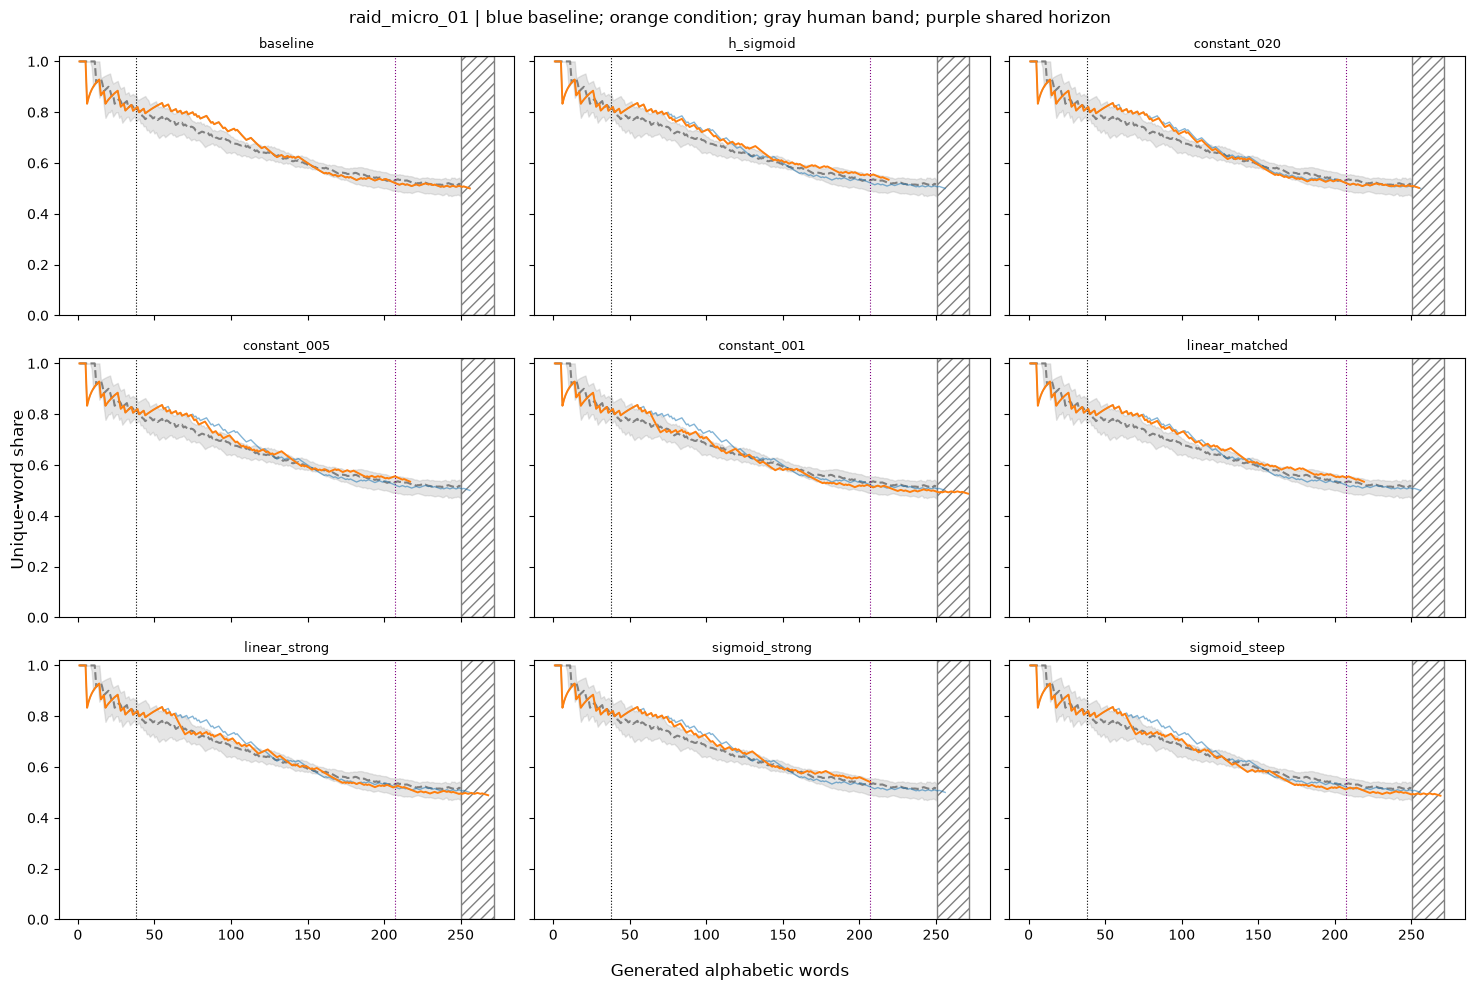

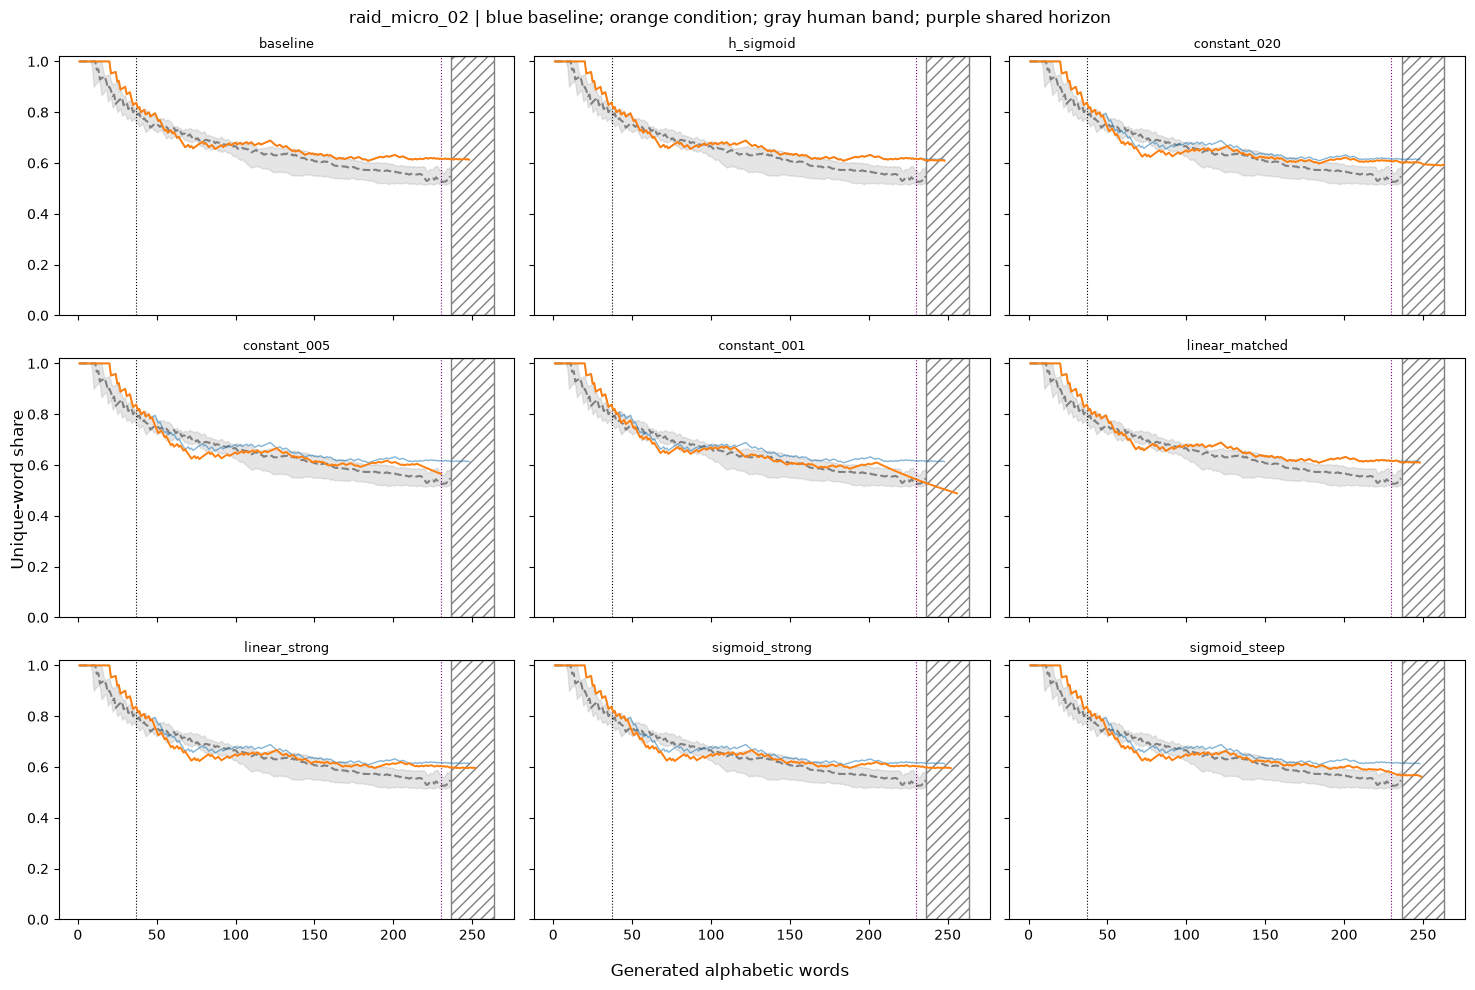

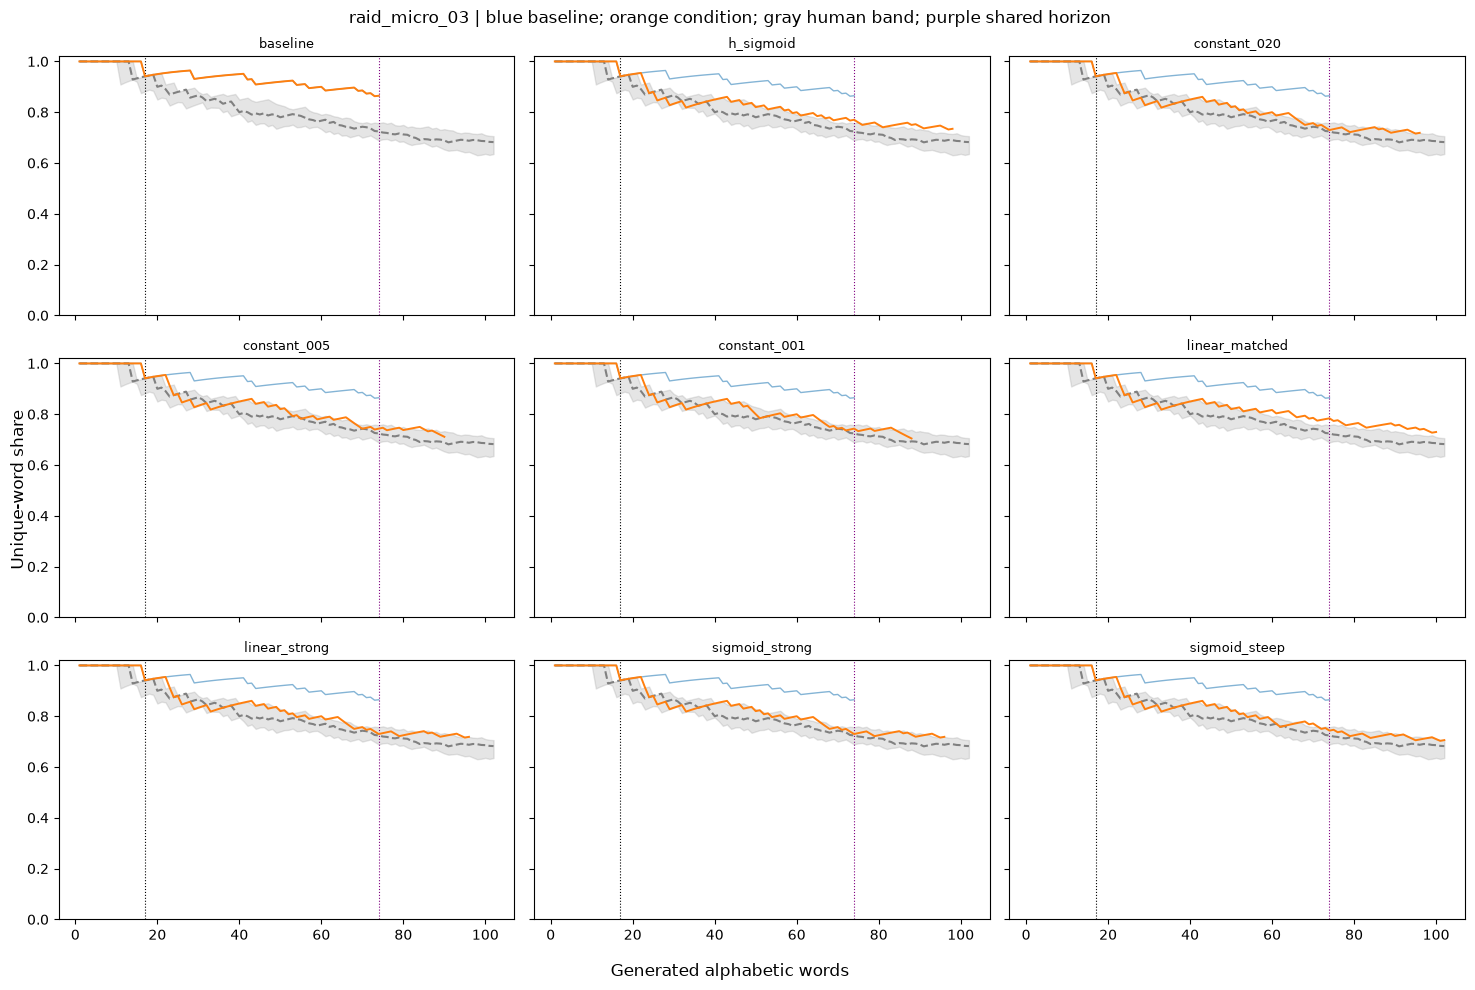

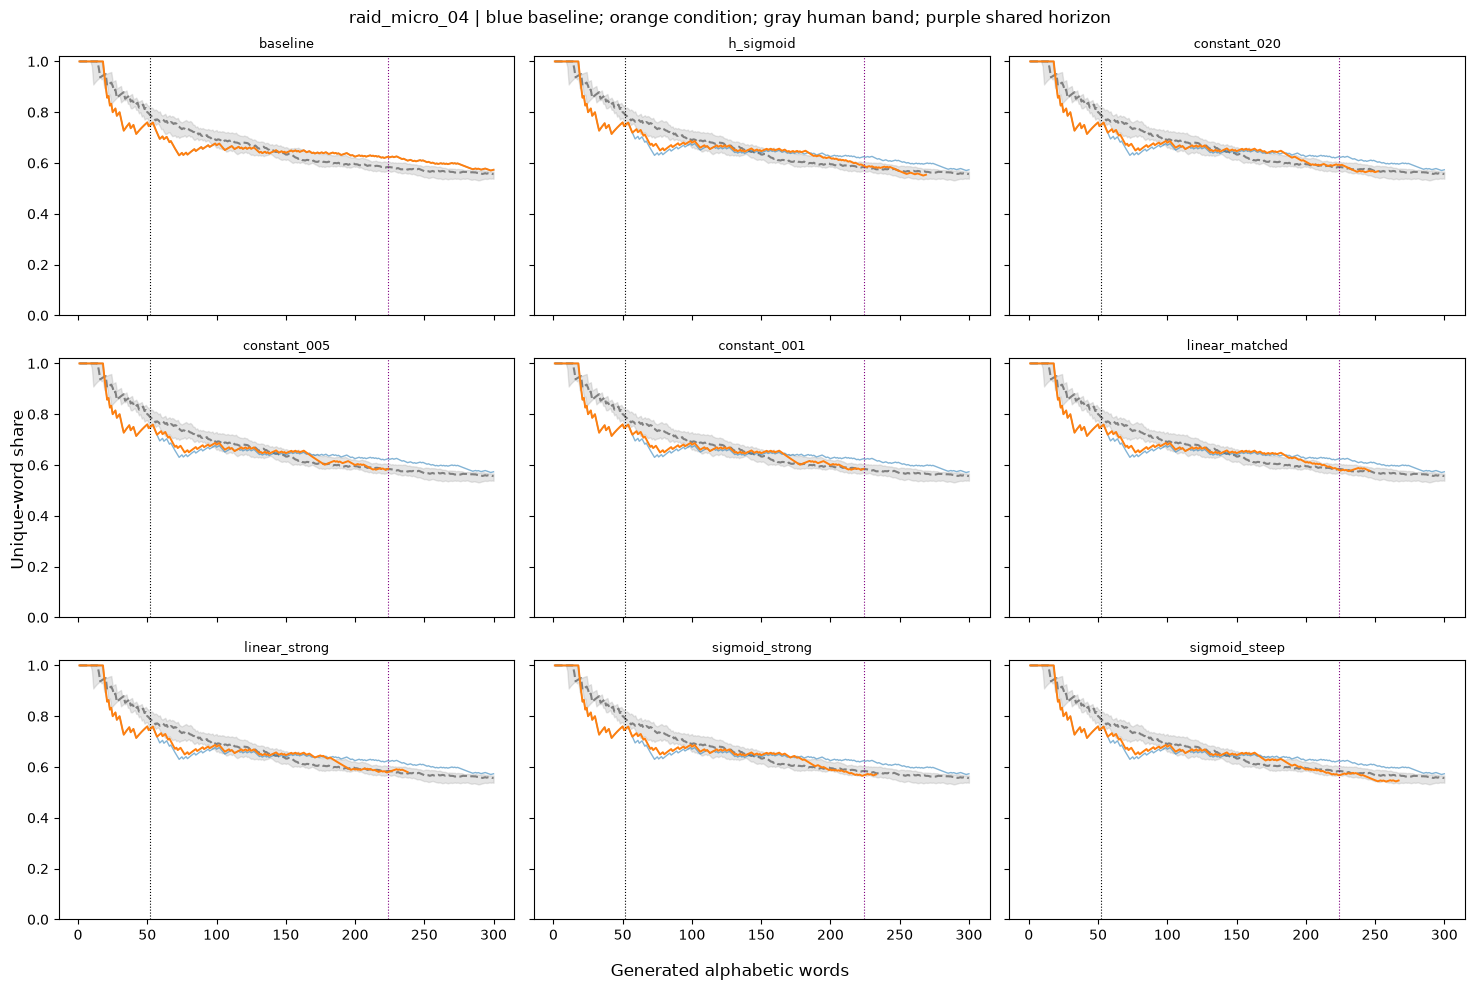

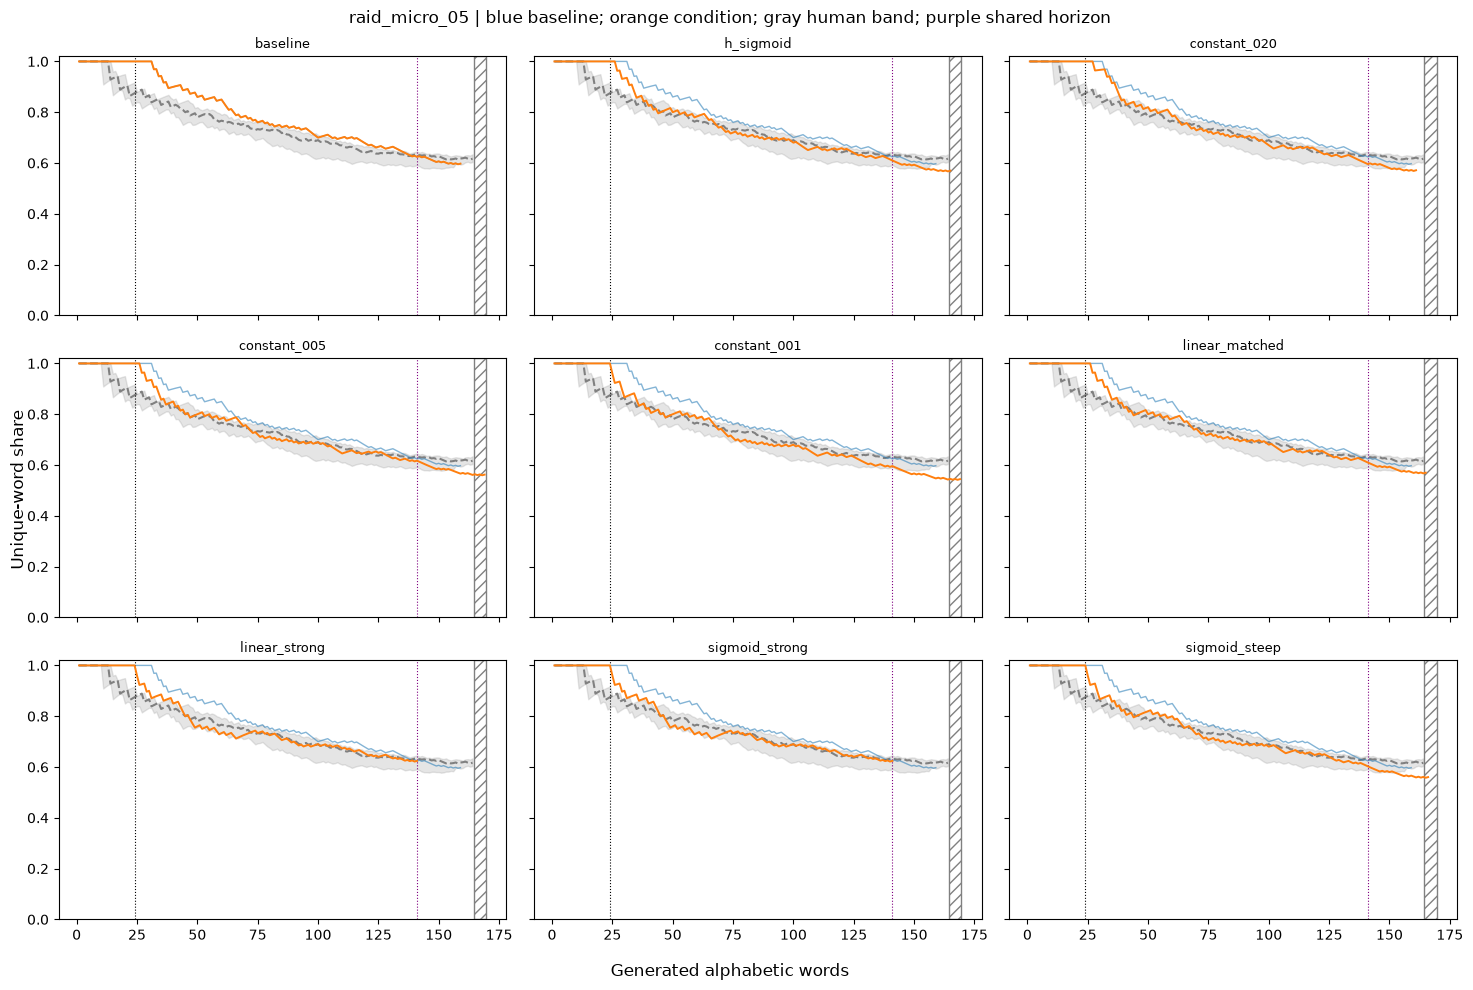

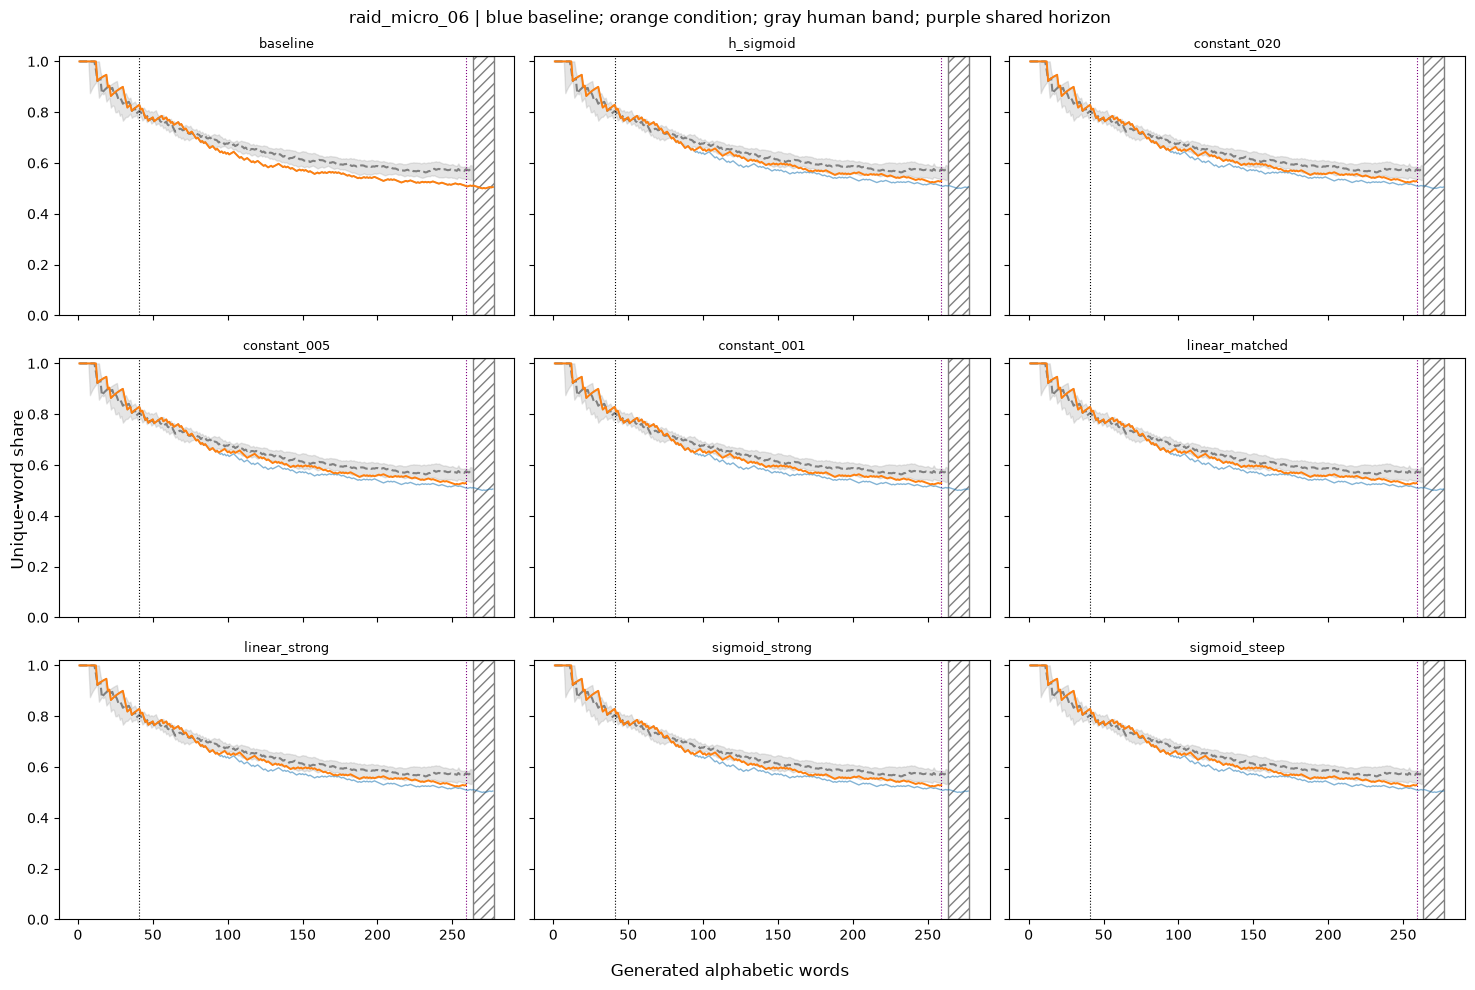

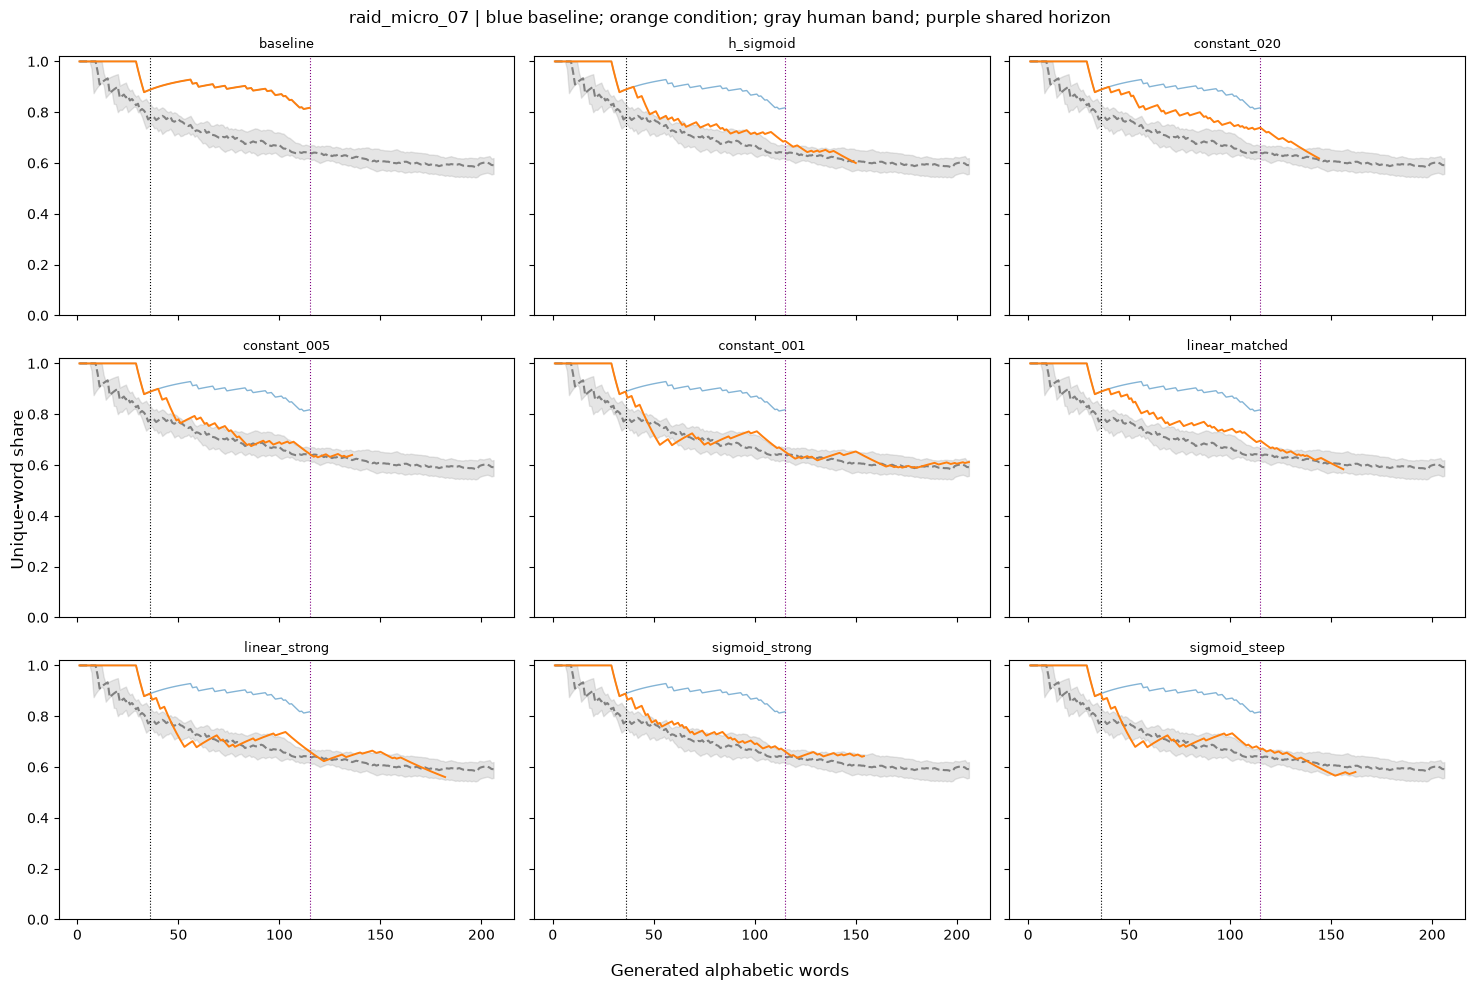

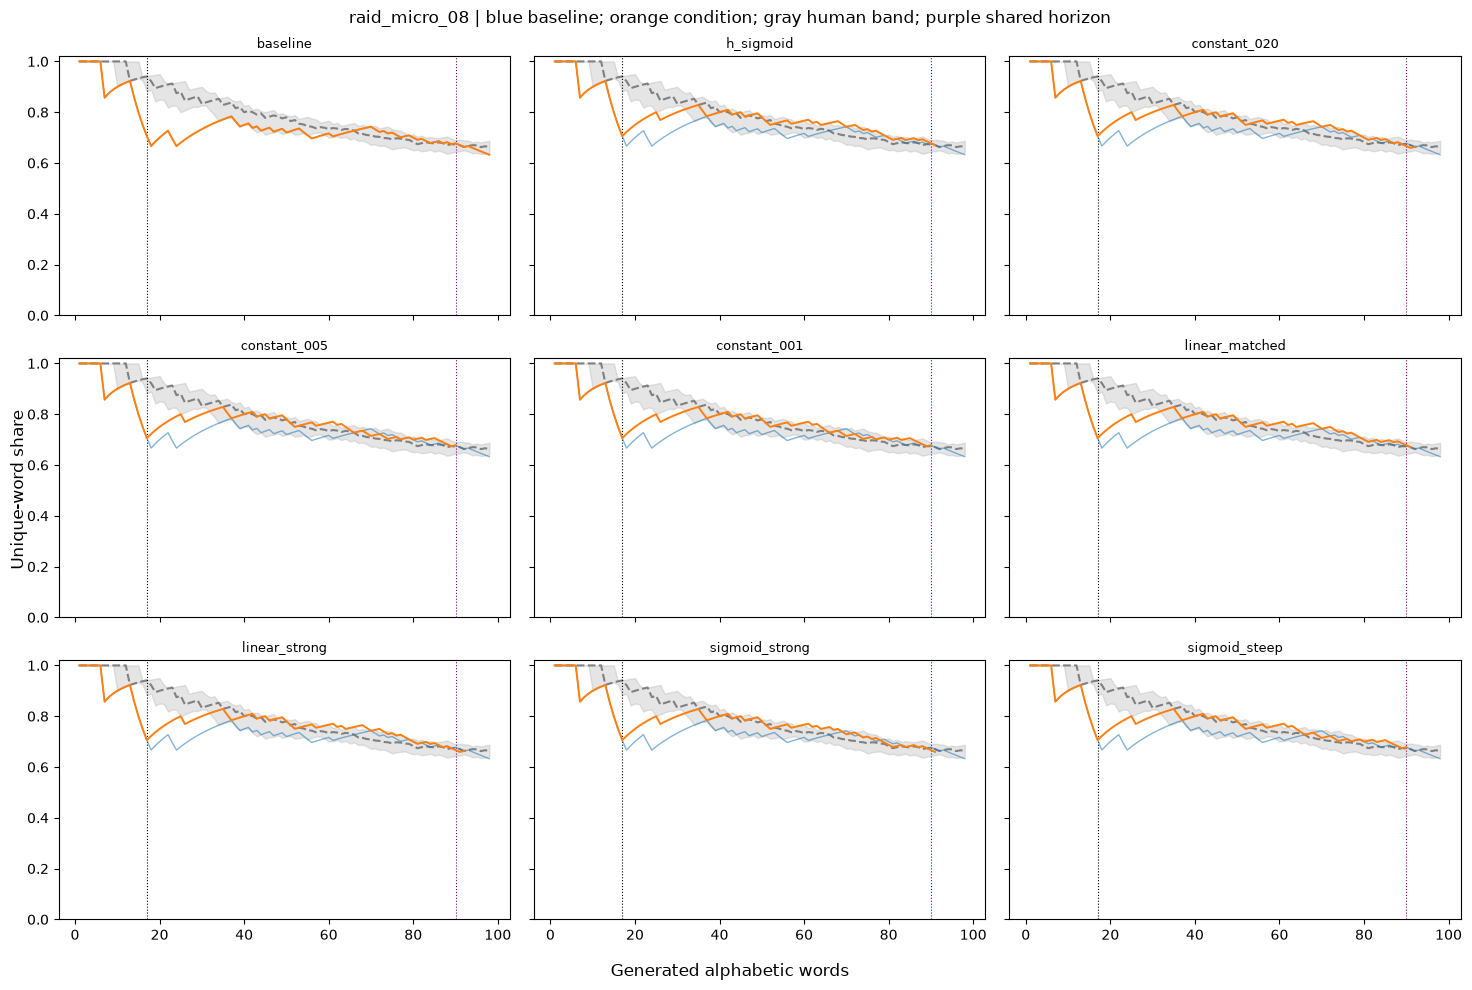

active_words  searches  replacements  fallbacks  \
condition      mode                                                        
constant_001   decrease           175       104            68         36   
               increase           424       219            13        206   
constant_005   decrease           248       163            71         92   
               increase           328       165            12        153   
constant_020   decrease           410       272            65        207   
               increase           373       190            12        178   
h_sigmoid      decrease           592       358            63        295   
               increase           309       156            12        144   
linear_matched decrease           572       357            72        285   
               increase           309       156            12        144   
linear_strong  decrease           369       225            59        166   
               increase           352       170            15        155   
sigmoid_steep  decrease           280       180            66        114   
               increase           453       230            18        212   
sigmoid_strong decrease           461       304            79        225   
               increase           348       172            17        155   

                         expanded_nodes  theta_min  theta_median  theta_max  \
condition      mode                                                           
constant_001   decrease            5695   0.001000      0.001000   0.001000   
               increase             522   0.005000      0.052500   0.097958   
constant_005   decrease            3594   0.005000      0.005000   0.005000   
               increase             409   0.005000      0.040848   0.097958   
constant_020   decrease            1303   0.020000      0.020000   0.020000   
               increase             461   0.005000      0.052500   0.097958   
h_sigmoid      decrease            3085   0.005003      0.045275   0.097941   
               increase             384   0.005001      0.047766   0.097958   
linear_matched decrease            2557   0.005000      0.040625   0.097361   
               increase             384   0.005001      0.047766   0.097958   
linear_strong  decrease            1199   0.001000      0.017333   0.047958   
               increase             424   0.005000      0.044953   0.097958   
sigmoid_steep  decrease            1382   0.001000      0.006841   0.049819   
               increase             564   0.005000      0.052500   0.097958   
sigmoid_strong decrease            1506   0.001006      0.014178   0.047056   
               increase             430   0.005000      0.052500   0.097958   

                         success_per_search  
condition      mode                          
constant_001   decrease            0.653846  
               increase            0.059361  
constant_005   decrease            0.435583  
               increase            0.072727  
constant_020   decrease            0.238971  
               increase            0.063158  
h_sigmoid      decrease            0.175978  
               increase            0.076923  
linear_matched decrease            0.201681  
               increase            0.076923  
linear_strong  decrease            0.262222  
               increase            0.088235  
sigmoid_steep  decrease            0.366667  
               increase            0.078261  
sigmoid_strong decrease            0.259868  
               increase            0.098837

In [13]:
for c in cases:
    available={name:states.get((c['case_id'],name)) for name in CONDITION_ORDER}
    horizon=max([len(s['words']) for s in available.values() if s]+[c['warmup_words']+1])
    ws=np.arange(1,horizon+1);refs=[reference_at(c['curve'],int(w)) for w in ws]
    fig,axes=plt.subplots(3,3,figsize=(15,10),sharex=True,sharey=True)
    shared=None
    if len(common):
        block=common.loc[common.case_id==c['case_id']]
        if len(block):shared=int(block.horizon.iloc[0])
    for ax,name in zip(axes.flat,CONDITION_ORDER):
        ax.fill_between(ws,[r.get('H_h30',np.nan) for r in refs],[r.get('H_a10',np.nan) for r in refs],color='gray',alpha=.2)
        ax.plot(ws,[r.get('H_h10',np.nan) for r in refs],color='gray',ls='--')
        ax.axvline(c['warmup_words'],color='black',ls=':',lw=.8)
        if shared is not None:ax.axvline(shared,color='purple',ls=':',lw=.8)
        unsupported=next((int(w) for w,r in zip(ws,refs) if not r['supported']),None)
        if unsupported:ax.axvspan(unsupported-.5,horizon+.5,facecolor='none',edgecolor='gray',hatch='///')
        b=available['baseline']
        if b:ax.plot([t['W_after'] for t in b['trajectory']],[t['k_after'] for t in b['trajectory']],color='tab:blue',alpha=.55,lw=1)
        s=available[name]
        if s:ax.plot([t['W_after'] for t in s['trajectory']],[t['k_after'] for t in s['trajectory']],color='tab:orange',lw=1.4)
        ax.set_title(name+(' (pending)' if not s else ' (incomplete)' if not s['finished'] else ''),fontsize=9)
        ax.set_ylim(0,1.02)
    fig.suptitle(c['case_id']+' | blue baseline; orange condition; gray human band; purple shared horizon')
    fig.supxlabel('Generated alphabetic words');fig.supylabel('Unique-word share');fig.tight_layout()
    fig.savefig(OUT/f"trajectory_grid_{c['case_id']}.png",dpi=180);plt.show()

search_rows=[]
for (case_id,name),s in states.items():
    for t in s['trajectory']:
        if t['mode_before'] not in ['increase','decrease']:continue
        search_rows.append(dict(case_id=case_id,condition=name,mode=t['mode_before'],
            theta=t['theta'],Q=t['Q'],searched=t['action'] in ['backtracked','fallback_exhausted'],
            replaced=t['action']=='backtracked',fallback=t['action']=='fallback_exhausted',
            expanded=t['search_expanded'],distinct_candidates=t.get('distinct_candidates',0)))
search_df=pd.DataFrame(search_rows)
if len(search_df):
    stats=search_df.groupby(['condition','mode']).agg(active_words=('mode','size'),searches=('searched','sum'),
        replacements=('replaced','sum'),fallbacks=('fallback','sum'),expanded_nodes=('expanded','sum'),
        theta_min=('theta','min'),theta_median=('theta','median'),theta_max=('theta','max'))
    stats['success_per_search']=stats.replacements/stats.searches.replace(0,np.nan)
    display(stats);stats.to_csv(OUT/'search_diagnostics.csv');search_df.to_csv(OUT/'active_word_diagnostics.csv',index=False)

## Full-text review for every condition
The review file preserves annotations on rerun and shows incomplete status explicitly. Inspect meaning/facts/omissions, grammar, repetition, genre/tone, and overall acceptability before favoring a stronger setting. No automatic language-quality judge is used. The cell prints three cases under a configurable setting and exports all texts; the selected setting is not chosen by detector performance.

In [14]:
review_rows=[]
for c in cases:
    b=states.get((c['case_id'],'baseline'))
    for name in CONDITION_ORDER[1:]:
        s=states.get((c['case_id'],name))
        review_rows.append(dict(case_id=c['case_id'],condition=name,status=s['status'] if s else 'not_started',
            original=c['original'],baseline=b['committed_text'] if b else '',controlled=s['committed_text'] if s else '',
            meaning_preserved='',facts_preserved='',no_major_omissions='',grammar_ok='',repetition_ok='',genre_tone_ok='',acceptable='',notes=''))
review=pd.DataFrame(review_rows);review_path=OUT/'manual_review.csv'
fields=['meaning_preserved','facts_preserved','no_major_omissions','grammar_ok','repetition_ok','genre_tone_ok','acceptable','notes']
if review_path.exists():
    previous_review=pd.read_csv(review_path,keep_default_na=False).set_index(['case_id','condition'])
    idx=pd.MultiIndex.from_frame(review[['case_id','condition']])
    for field in fields:review[field]=previous_review[field].reindex(idx).fillna('').to_numpy()
review.to_csv(review_path,index=False)
REVIEW_CONDITION='sigmoid_strong'
REVIEW_CASE_IDS=['raid_micro_03','raid_micro_06','raid_micro_07']
for row in review.loc[(review.condition==REVIEW_CONDITION)&review.case_id.isin(REVIEW_CASE_IDS)].itertuples():
    display(HTML(f'<h3>{html.escape(row.case_id)} — {html.escape(row.condition)} — {html.escape(row.status)}</h3>'))
    for label,text in [('ORIGINAL AI',row.original),('BASELINE',row.baseline),('CONTROLLED',row.controlled)]:
        print(label);print(text);print()

ORIGINAL AI
I'm sure many preppers out there have heard about lifeboats, but how much is enough? It's important to have a plan in place and supplies stockpiled for when SHTF, but it can be overwhelming to figure out what you need and how much of it. In my experience, I've found that having at least three months' worth of food and water, as well as essentials like medicine and hygiene products, is a good starting point. But don't stop there! Keep adding to your stash and learning new skills so that you're always prepared for whatever comes your way. Remember, knowledge is power - stay informed and stay safe!

BASELINE
Many preppers are familiar with lifeboats, but how much supplies should one have? It's crucial to have a preparedness plan and stockpile essential items like food, water, medicine, and hygiene products. In my experience, having at least three months' worth of supplies is a good starting point. However, don't stop there! Keep adding to your stash and learning new skills to 

ORIGINAL AI
In the small town of Willow Creek, a brutal murder shakes the community to its core. The Robins family, known for their kindness and generosity, are found dead in their home, each victim bearing the signs of a gruesome and violent attack. As the local police department investigates, they are met with a web of secrets and deceit that threaten to tear the town apart.

As the investigation unfolds, the police are faced with a multitude of suspects, each with their own motives and secrets. There's the Robins' neighbors, the Smiths, who had a long-standing feud with the family. There's also the local businessman, Mr. Johnson, who had a history of shady dealings with the Robins. And then there's the mysterious stranger who was seen lurking around the Robins' home on the night of the murders.

As the police dig deeper, they uncover a tangled web of lies and deceit that leads them to question everyone they thought they could trust. The townspeople are shocked to discover that their

ORIGINAL AI
Azaleas unfold blushing gowns, beneath the pecan trees,
The magnolias blossom, carried on the soft, warm breeze
Rivers carry golden pollen, the essence of the pines,
Sweet aroma fills the air from confederate jasmine vines.

Redbud trees in bloom against a clear Carolina blue,
Spanish moss gently hangs, creating an ethereal view.
Cardinals flutter, gifting spots of fiery, passionate red,
Tender footsteps of a deer, where the camellia petals spread.

Wisteria weaves a blanket, lilac clusters hanging fair,
In the field of buttercups, sunlight creates an amber glare.
Mockingbirds reciting songs, in the southern live oak’s shade,
A quartet of melody and colour, a symphony, nature-made.

The song of the cicadas echoes, as day gives into evening's hush,
Fireflies begin their dance, in the mellow dusk-light rush.
The promise of humid nights, under a moon laced with silver touch,
Such is the bewitching charm, of a southern springtime’s clutch. 

Its warmth seeps into your bones, li

## Frozen detector scores (secondary)
Run after generation. All completed rewrites are scored; missing/incomplete runs remain missing, never replaced by originals. Summary means use only cases completed under every planned condition, so conditions are compared on the same cases. These scores are descriptive detector outputs, not calibrated authorship probabilities. Review acceptability separately. The exact C02e2 extractor is embedded and verified against cached original features.

In [15]:
import re, pickle
from collections import Counter
import textstat
PUNCTUATION = [('comma', ','), ('period', '.'), ('colon', ':'), ('semicolon', ';'),
    ('question', '?'), ('exclamation', '!'), ('hyphen', '-'), ('quote', '"'),
    ('lparen', '('), ('rparen', ')'), ('lbracket', '['), ('rbracket', ']'), ('newline', '\n')]
google_words=[w.strip().lower() for w in (BASE/'google-10000-english.txt').read_text().splitlines() if w.strip()]
GOOGLE_TOP={n:set(google_words[:n]) for n in [100,1000,10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector

condition,original,baseline,h_sigmoid,constant_020,constant_005,constant_001,linear_matched,linear_strong,sigmoid_strong,sigmoid_steep
case_id,,,,,,,,,,
raid_micro_01,0.649867,0.687626,0.607102,0.670221,0.595147,0.668436,0.607102,0.633300,0.621317,0.662216
raid_micro_02,0.651501,0.572330,0.567469,0.560374,0.640252,0.683718,0.567469,0.587712,0.587712,0.601893
raid_micro_03,0.660483,0.702749,0.571638,0.661000,0.642710,0.556885,0.652606,0.661000,0.661000,0.579272
raid_micro_04,0.660908,0.673229,0.655904,0.665491,0.648998,0.648998,0.674784,0.683010,0.672713,0.674304
raid_micro_05,0.590246,0.609352,0.565913,0.554304,0.557287,0.700779,0.565913,0.601126,0.601126,0.649633
raid_micro_06,0.590607,0.595183,0.556930,0.556930,0.556930,0.556930,0.556930,0.556930,0.556930,0.556930
raid_micro_07,0.591105,0.613333,0.569922,0.565774,0.570141,0.555159,0.580679,0.623098,0.652244,0.605633
raid_micro_08,0.593705,0.550241,0.536791,0.560817,0.594960,0.594960,0.536791,0.560817,0.530951,0.594960


Score change vs baseline: negative = lower AI score.


condition,h_sigmoid,constant_020,constant_005,constant_001,linear_matched,linear_strong,sigmoid_strong,sigmoid_steep
case_id,,,,,,,,
raid_micro_01,-0.080524,-0.017405,-0.092479,-0.019190,-0.080524,-0.054326,-0.066309,-0.025410
raid_micro_02,-0.004861,-0.011956,0.067921,0.111388,-0.004861,0.015382,0.015382,0.029563
raid_micro_03,-0.131110,-0.041749,-0.060039,-0.145864,-0.050142,-0.041749,-0.041749,-0.123477
raid_micro_04,-0.017325,-0.007738,-0.024231,-0.024231,0.001554,0.009780,-0.000516,0.001075
raid_micro_05,-0.043439,-0.055049,-0.052066,0.091427,-0.043439,-0.008226,-0.008226,0.040280
raid_micro_06,-0.038253,-0.038253,-0.038253,-0.038253,-0.038253,-0.038253,-0.038253,-0.038253
raid_micro_07,-0.043411,-0.047558,-0.043192,-0.058174,-0.032654,0.009765,0.038911,-0.007700
raid_micro_08,-0.013450,0.010576,0.044719,0.044719,-0.013450,0.010576,-0.019290,0.044719


,condition,n_cases,mean_AI_score,mean_change_vs_baseline,cases_lower_than_baseline
0,baseline,8,0.625505,0.000000,0
1,h_sigmoid,8,0.578959,-0.046547,8
2,constant_020,8,0.599364,-0.026142,7
3,constant_005,8,0.600803,-0.024702,6
4,constant_001,8,0.620733,-0.004772,5
5,linear_matched,8,0.592784,-0.032721,7
6,linear_strong,8,0.613374,-0.012131,4
7,sigmoid_strong,8,0.610499,-0.015006,6
8,sigmoid_steep,8,0.615605,-0.009900,4


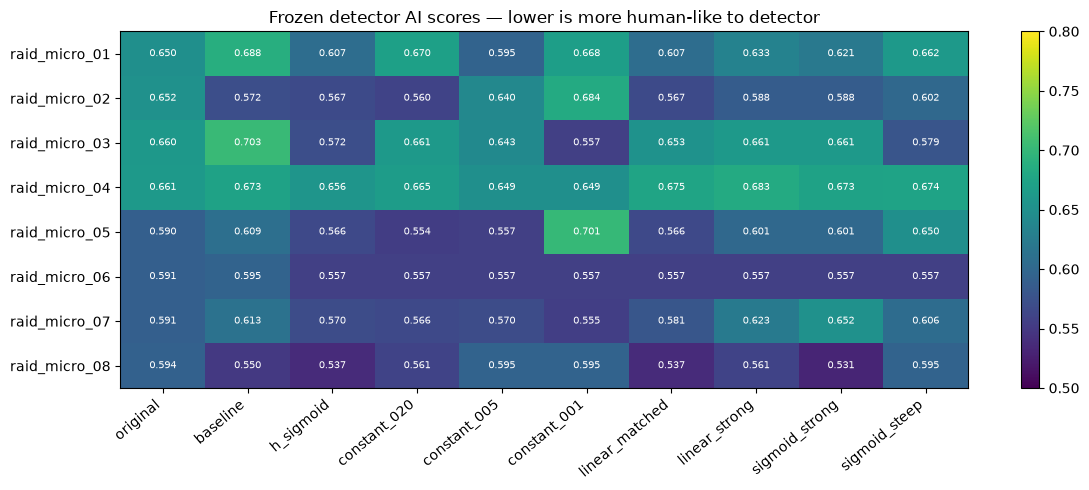

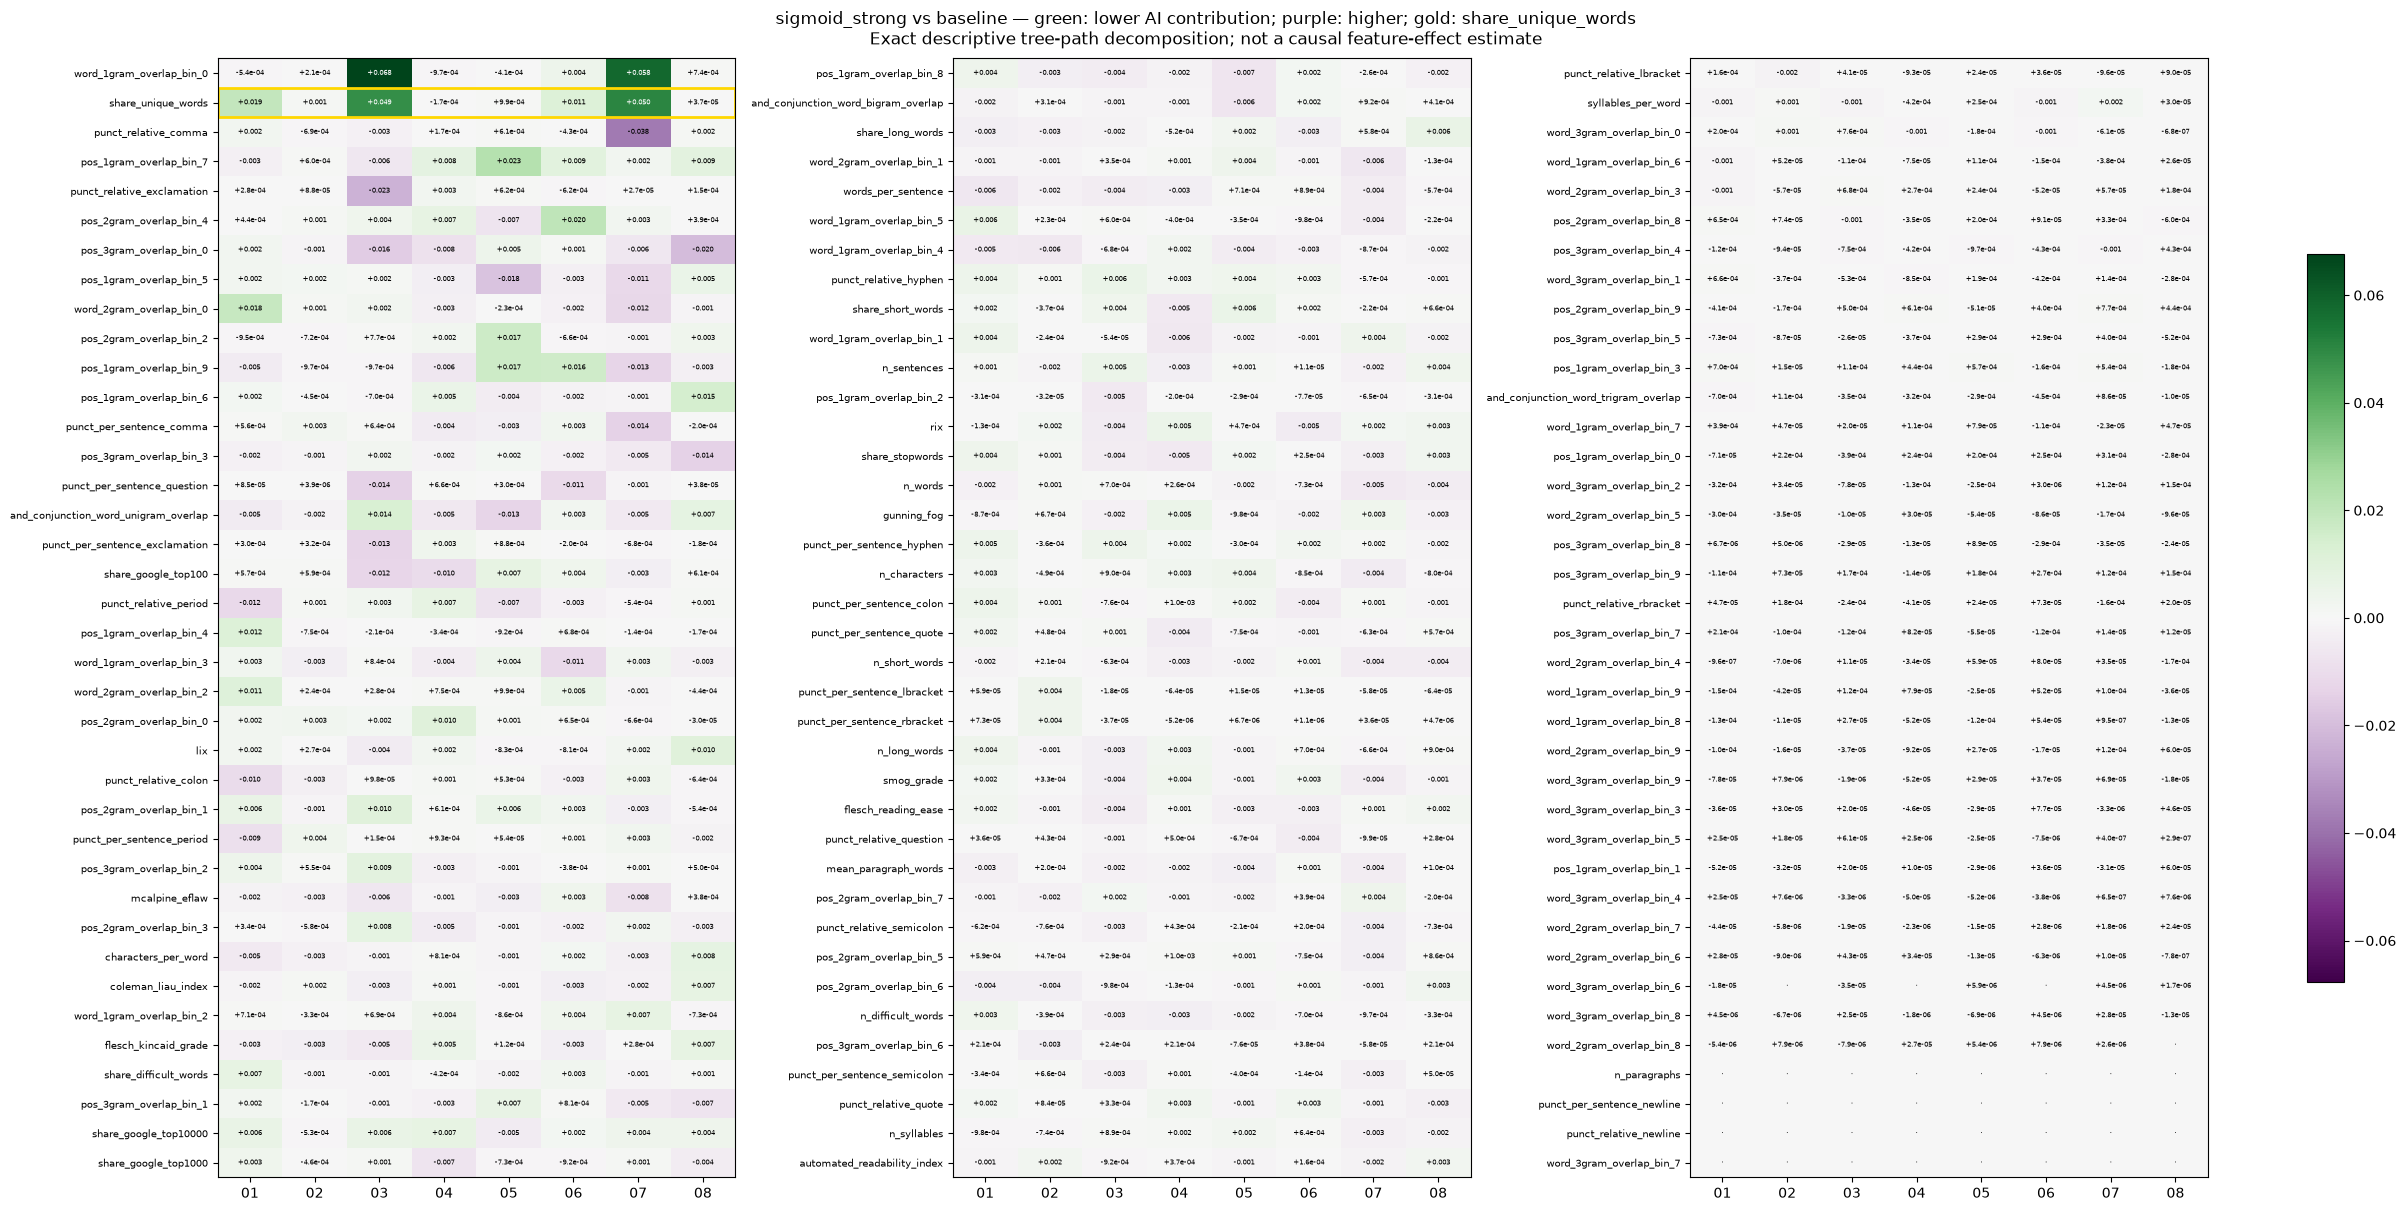

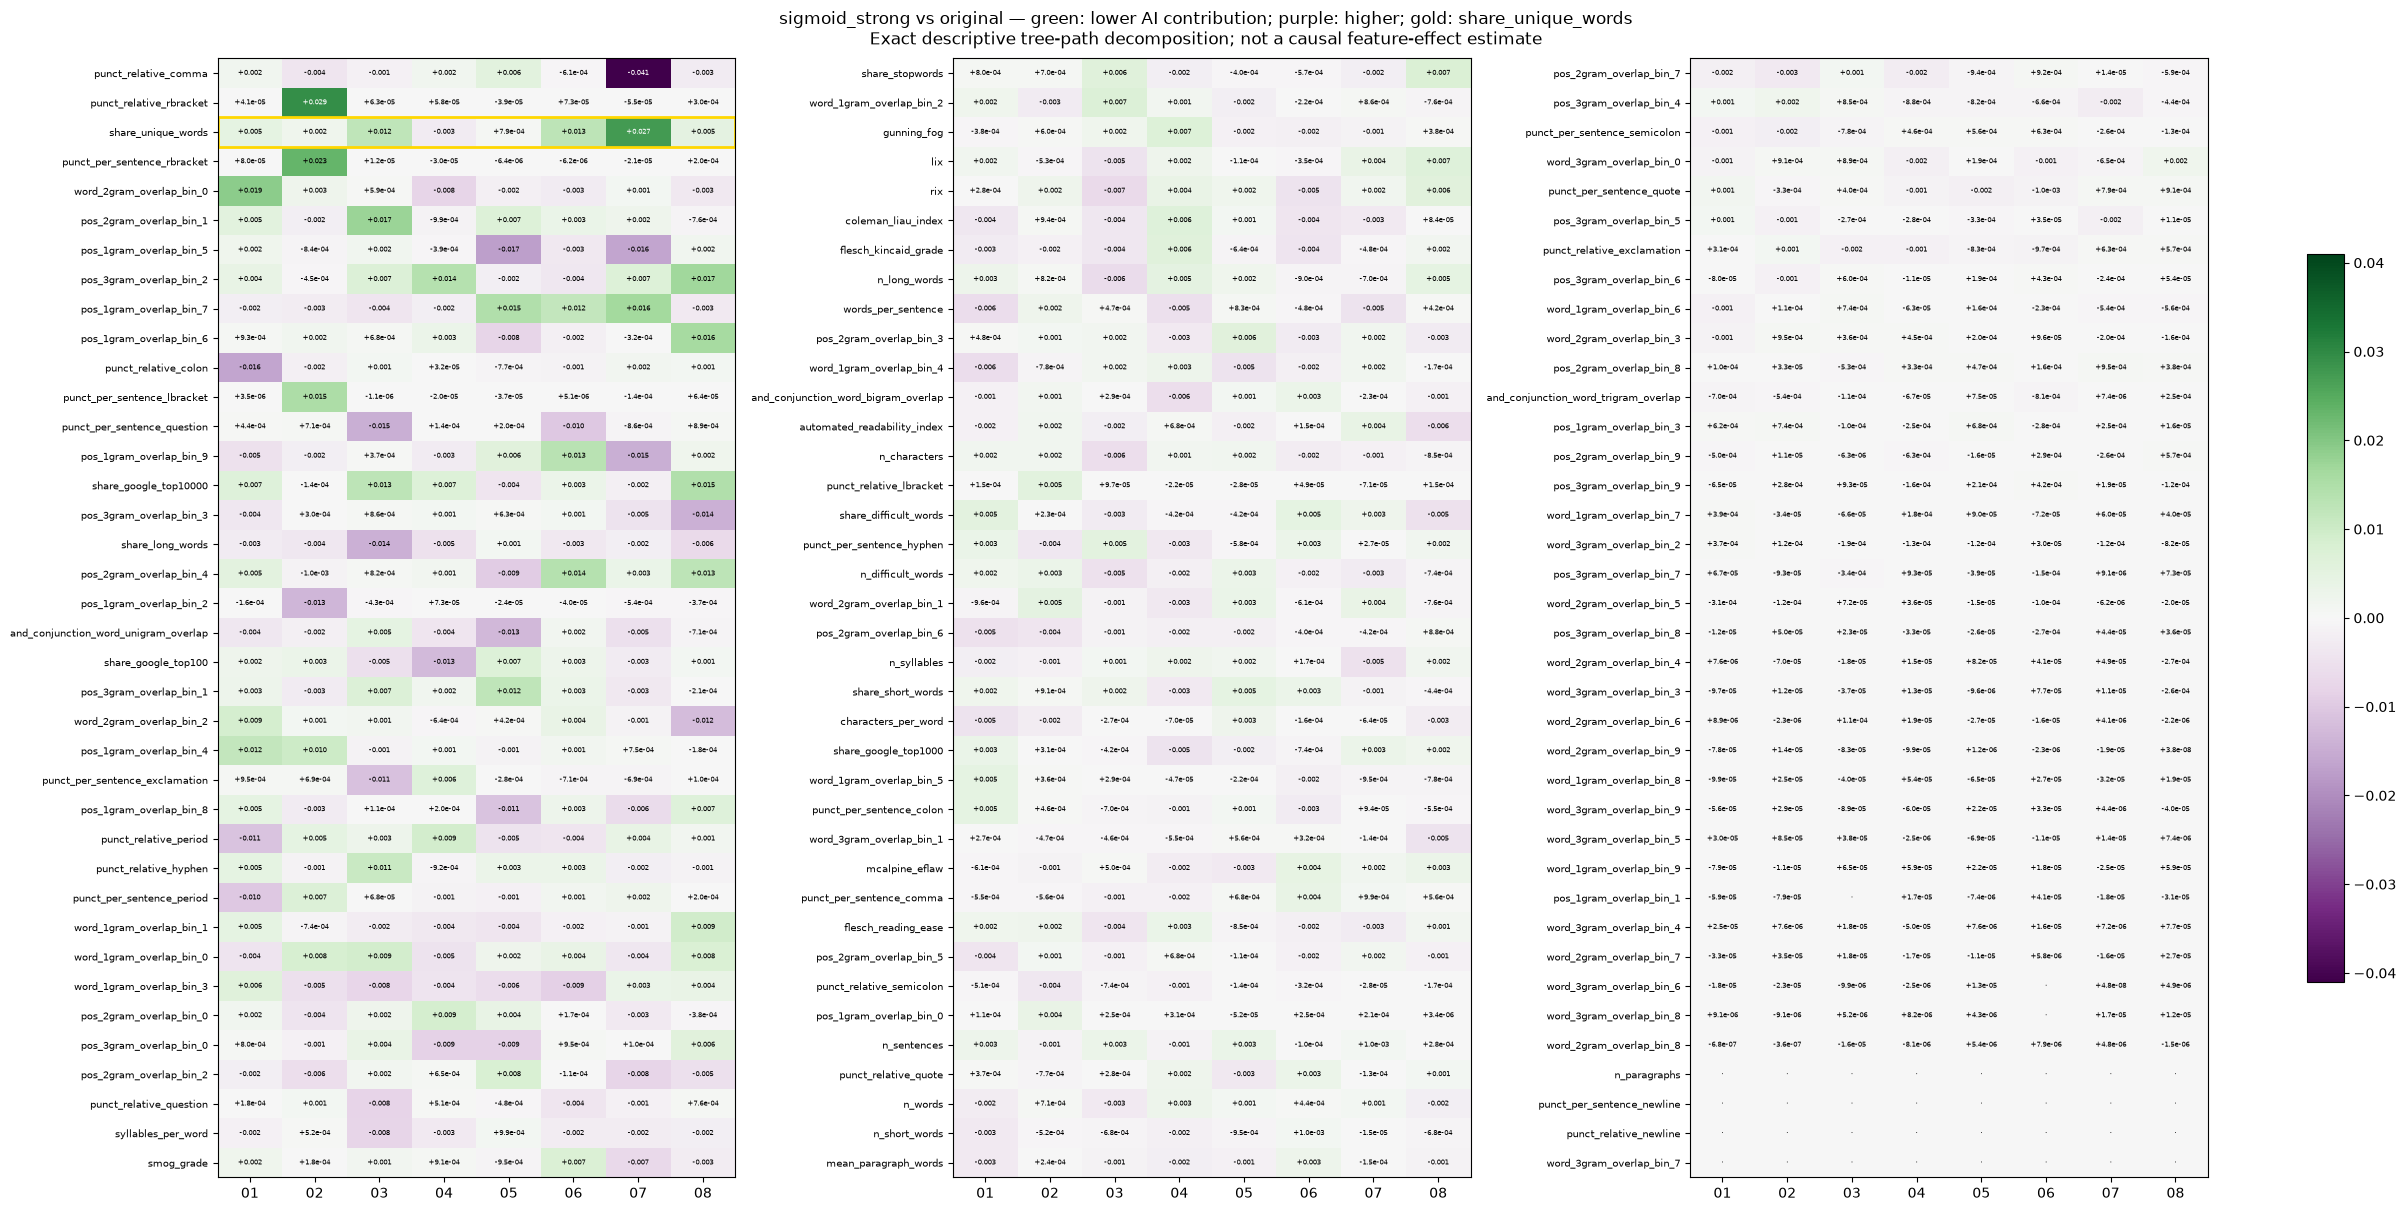

In [21]:
from matplotlib.patches import Rectangle
FEATURE_NAMES=json.loads((BASE/'fz118_feature_contract.json').read_text())['feature_names']
model_features=json.loads((PRIOR/'fz118_raid_model_features.json').read_text())
with (PRIOR/'fz118_raid_no_parentheses_detector.pkl').open('rb') as f:detector=pickle.load(f)
assert list(detector.classes_)==[0,1]
records=[];vectors=[]
for c in cases:
    vector=extract_fz118(c['original'].translate(str.maketrans({'\n':' ','\r':' '})))
    np.testing.assert_allclose(vector,feature_map.loc[c['source_id'],FEATURE_NAMES].to_numpy(float),atol=1e-9,rtol=0)
    records.append(dict(case_id=c['case_id'],condition='original'));vectors.append(vector)
    for name in CONDITION_ORDER:
        s=states.get((c['case_id'],name))
        if not s or not s['finished'] or s['status']!='completed_eos':continue
        records.append(dict(case_id=c['case_id'],condition=name))
        vectors.append(extract_fz118(s['committed_text'].translate(str.maketrans({'\n':' ','\r':' '}))))
raw=pd.DataFrame(vectors,columns=FEATURE_NAMES);frame=raw[model_features]
scores=pd.DataFrame(records);scores['AI_score']=detector.predict_proba(frame)[:,1]
wide=scores.pivot(index='case_id',columns='condition',values='AI_score').reindex(columns=['original']+CONDITION_ORDER)
display(wide.round(6));wide.to_csv(OUT/'detector_scores_wide.csv');scores.to_csv(OUT/'detector_scores_long.csv',index=False)
pd.concat([scores[['case_id','condition']],raw],axis=1).to_csv(OUT/'all_detector_features.csv',index=False)
deltas=wide[CONDITION_ORDER[1:]].subtract(wide.baseline,axis=0)
print('Score change vs baseline: negative = lower AI score.');display(deltas.round(6));deltas.to_csv(OUT/'detector_deltas_vs_baseline.csv')
matched=wide.dropna(subset=CONDITION_ORDER)
if len(matched):
    aggregates=[]
    for name in CONDITION_ORDER:
        delta=matched[name]-matched.baseline
        aggregates.append(dict(condition=name,n_cases=len(matched),mean_AI_score=matched[name].mean(),
            mean_change_vs_baseline=delta.mean(),cases_lower_than_baseline=int((delta<0).sum())))
    display(pd.DataFrame(aggregates))
else:print('Matched detector summary pending completion of all conditions for at least one case.')
fig,ax=plt.subplots(figsize=(12,5));im=ax.imshow(wide.to_numpy(),vmin=0,vmax=1,cmap='viridis',aspect='auto')
ax.set_xticks(range(len(wide.columns)),wide.columns,rotation=40,ha='right');ax.set_yticks(range(len(wide.index)),wide.index)
for i,row in enumerate(wide.to_numpy()):
    for j,value in enumerate(row):ax.text(j,i,f'{value:.3f}' if np.isfinite(value) else 'pending',ha='center',va='center',fontsize=7,color='white')
ax.set_title('Frozen detector AI scores — lower is more human-like to detector');im.set_clim(0.5, 0.8);fig.colorbar(im,ax=ax)
fig.tight_layout();fig.savefig(OUT/'detector_score_heatmap.png',dpi=180);plt.show()

X=frame.to_numpy(np.float32);contributions=np.zeros(X.shape);bias=0.
for est in detector.estimators_:
    t=est.tree_;v=t.value[:,0,:];p=v[:,1]/v.sum(axis=1);bias+=p[0]
    for row in range(len(X)):
        node=0
        while t.feature[node]>=0:
            j=t.feature[node];child=t.children_left[node] if X[row,j]<=t.threshold[node] else t.children_right[node]
            contributions[row,j]+=p[child]-p[node];node=child
contributions/=len(detector.estimators_);bias/=len(detector.estimators_)
np.testing.assert_allclose(bias+contributions.sum(axis=1),scores.AI_score,atol=1e-9,rtol=0)
cf=pd.DataFrame(contributions,index=pd.MultiIndex.from_frame(scores[['case_id','condition']]),columns=model_features)
cf.to_csv(OUT/'all_feature_contributions.csv')
# Save all comparisons; visualize a declared condition, not an automatic winner.
HEATMAP_CONDITION='sigmoid_strong'
for name in CONDITION_ORDER[1:]:
    if name not in cf.index.get_level_values('condition'):continue
    target=cf.xs(name,level='condition')
    for reference in ['baseline','original']:
        if reference not in cf.index.get_level_values('condition'):continue
        before=cf.xs(reference,level='condition');ids=target.index.intersection(before.index)
        if not len(ids):continue
        movement=(before.loc[ids]-target.loc[ids]).T
        np.testing.assert_allclose(movement.sum(axis=0),wide.loc[ids,reference]-wide.loc[ids,name],atol=1e-9,rtol=0)
        movement.to_csv(OUT/f'contribution_{name}_vs_{reference}.csv')
        if name!=HEATMAP_CONDITION:continue
        order=movement.abs().max(axis=1).sort_values(ascending=False).index
        limit=max(float(movement.abs().to_numpy().max()),1e-8)
        fig,axes=plt.subplots(1,3,figsize=(24,12),layout='constrained')
        for ax,block in zip(axes,np.array_split(np.array(order),3)):
            data=movement.loc[block];im=ax.imshow(data,cmap='PRGn',vmin=-limit,vmax=limit,aspect='auto')
            ax.set_yticks(range(len(block)),block,fontsize=7);ax.set_xticks(range(len(ids)),[c.replace('raid_micro_','') for c in ids])
            for row,feature in enumerate(block):
                if feature=='share_unique_words':ax.add_patch(Rectangle((-.5,row-.5),len(ids),1,fill=False,edgecolor='gold',lw=2))
                for col,value in enumerate(data.iloc[row]):
                    label='·' if abs(value)<1e-9 else f'{value:+.3f}' if abs(value)>=.001 else f'{value:+.1e}'
                    ax.text(col,row,label,ha='center',va='center',fontsize=5,color='white' if abs(value)>.6*limit else 'black')
        fig.suptitle(f'{name} vs {reference} — green: lower AI contribution; purple: higher; gold: share_unique_words\nExact descriptive tree-path decomposition; not a causal feature-effect estimate')
        fig.colorbar(im,ax=list(axes),shrink=.65);fig.savefig(OUT/f'heatmap_{name}_vs_{reference}.png',dpi=180,bbox_inches='tight');plt.show()